# TFI Teoría de Control: control automático de presión de descarga
**Pedro Mazzieri y Victoria Yedid** · Prof. Omar Civale

Simulación del lazo de presión de una estación de bombeo de un oleoducto de crudo: controlador PID en el PLC (con la derivativa inhibida, es decir PI), variador y bomba, tramo de 80 km y transmisor de presión, con una capa de supervisión (detección de fugas y disparo por alta presión).

Es el mismo modelo que `simulacion_presion.py` y que el tablero web. Versión final (noviembre de 2026): incluye solo P, solo I y solo D, el error en estado estable y la demora que tolera el lazo, que se pidieron en la defensa del 31/10. Para usarlo en Google Colab: *Entorno de ejecución → Ejecutar todas*.

**Contenido**
1. Parámetros del modelo
2. El lazo (un ciclo del PLC por segundo)
3. Calidad de servicio: cuándo una perturbación pasa a ser falla
4. ¿Hace falta el lazo? ¿Alcanza con P?
5. Estabilidad: Routh-Hurwitz
6. Escenarios con todas las señales (1 a 10)
7. Cada acción por separado y error en estado estable
8. Latencia: margen de fase y demora crítica
9. Tablero: simulación en tiempo real

## 1. Parámetros del modelo
Valores típicos supuestos, salvo el caudal nominal, que sale del caso documentado.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Proceso Gp: tramo de 80 km entre estaciones (oleoducto de 32")
L, D, e = 80e3, 0.8128, 0.0127
K_CRUDO, E_ACERO = 15000.0, 2.07e6                                  # [bar]
C_L = np.pi / 4 * D**2 * L * (1 / K_CRUDO + D / (e * E_ACERO))       # capacitancia [m3/bar]
P_NOM, P_SIG = 60.0, 5.0                                             # valor nominal y presión en la estación siguiente [bar]
Q_NOM = 1900.0                                                       # caudal nominal [m3/h]
K_OUT = Q_NOM / (P_NOM - P_SIG)                                      # [m3/h por bar]
P_MAX = 70.0                                                         # presión máxima admisible del caño [bar]

# Actuador Ga (variador + bomba) y elemento de medición H (transmisor)
K_B = 25.0                  # caudal de la bomba por % de velocidad [m3/h por %]
TAU_V = 10.0 / 3600         # rampa del variador: 10 s [h]
TAU_T = 1.0 / 3600          # transmisor con amortiguamiento: 1 s [h]
SIG_P, SIG_Q = 0.05, 10.0   # ruido del transmisor [bar] y de los caudalímetros [m3/h]
TS = 1.0 / 3600             # ciclo del PLC: 1 s [h]
U0 = Q_NOM / K_B            # velocidad de régimen [%]

# Controlador Gc: PID del PLC con la derivativa inhibida (PI)
KP = 10.0                   # [% por bar]
KI = 400.0                  # [% por bar·h]  (= 6,67 % por bar·min; tiempo integral 1,5 min)
KV = 0.0                    # derivativa [% por bar/min]; 0 = inhibida
TAU_D = 5.0 / 3600          # filtro de la derivativa: 5 s [h]

tau_p = C_L / K_OUT
print(f"C_L = {C_L:.2f} m3/bar   k_out = {K_OUT:.1f} m3/h por bar   τp = {tau_p*60:.1f} min   U0 = {U0:.0f} %")
print(f"θi = 4 + 0,16·{P_NOM:.0f} = {4 + 0.16*P_NOM:.1f} mA")

C_L = 4.05 m3/bar   k_out = 34.5 m3/h por bar   τp = 7.0 min   U0 = 76 %
θi = 4 + 0,16·60 = 13.6 mA


## 2. El lazo
Cada llamada a `paso()` es un ciclo del PLC (1 s): el transmisor mide, el PLC compara y calcula el PID, el variador mueve la bomba y el tramo convierte el caudal en presión. La supervisión usa instrumentos propios, independientes del transmisor del lazo.

Perturbaciones que se pueden aplicar:
* `k_out` menor: baja la demanda aguas abajo (θd, dentro del lazo).
* `fuga`: caudal que se escapa del tramo [m³/h] (θd, dentro del lazo).
* `n`: error que se suma a la lectura del transmisor [bar] (perturbación en la medición, en la realimentación).

In [2]:
class Lazo:
    def __init__(self, kp=KP, ki=KI, kv=KV, vn=P_NOM, supervision=True, seed=1):
        self.rng = np.random.default_rng(seed)
        self.kp, self.ki, self.kv, self.vn, self.supervision = kp, ki, kv, vn, supervision
        self.theta_o, self.P_med, self.f_filt = vn, vn, vn
        self.Q_b = K_OUT * (vn - P_SIG)                         # arranca en equilibrio
        self.integ = (self.Q_b / K_B - U0) / ki if ki > 0 else 0.0
        self.k_out, self.fuga, self.n = K_OUT, 0.0, 0.0
        self.parada, self.motivo = None, None
        self.buf, self.p_sup, self.k = [], [], 0

    def paso(self):
        t = self.k                                              # segundos de proceso
        Q_f = self.fuga if self.parada is None else 0.0          # la parada aísla el tramo

        # H: elemento de medición, con ruido y la perturbación n
        self.P_med += TS / TAU_T * (self.theta_o - self.P_med)
        f = self.P_med + self.rng.normal(0, SIG_P) + self.n

        # Σ y Gc: error y PID (derivativa sobre la medición filtrada), saturación y anti-windup
        err = self.vn - f
        f_prev = self.f_filt
        self.f_filt += TS / TAU_D * (f - self.f_filt)
        uP, uI = self.kp * err, self.ki * self.integ
        uD = -self.kv * (self.f_filt - f_prev) / (TS * 60)
        u = U0 + uP + uI + uD
        if 0.0 < u < 100.0:
            self.integ += err * TS
        u = min(max(u, 0.0), 100.0)
        if self.parada is not None:
            u = 0.0

        # Ga y Gp: actuador y proceso
        self.Q_b += TS / TAU_V * (K_B * u - self.Q_b)
        Q_out = self.k_out * (self.theta_o - P_SIG)
        self.theta_o += TS * (self.Q_b - Q_out - Q_f) / C_L

        # Supervisión: balance de caudal corregido por empaque de línea (30 s) y disparo por alta presión
        self.buf.append((self.Q_b + self.rng.normal(0, SIG_Q)) - (Q_out + self.rng.normal(0, SIG_Q)))
        self.p_sup.append(self.theta_o + self.rng.normal(0, SIG_P))
        self.buf, self.p_sup = self.buf[-30:], self.p_sup[-30:]
        balance = np.mean(self.buf) - C_L * (self.p_sup[-1] - self.p_sup[0]) / ((len(self.p_sup) - 1) * TS + 1e-9)
        if self.supervision and self.parada is None:
            if balance > 150.0 and self.k > 60:
                self.parada, self.motivo = t, "fuga"
            elif self.theta_o > P_MAX:
                self.parada, self.motivo = t, "alta presión"

        self.k += 1
        theta_d = (K_OUT - self.k_out) * (self.theta_o - P_SIG) - Q_f
        return dict(t=t, theta_i=self.vn, e=err, u=u, uP=uP, uI=uI, uD=uD, Q_b=self.Q_b, Q_out=Q_out,
                    theta_d=theta_d, theta_o=self.theta_o, n=self.n, f=f, balance=balance)

## 3. Calidad de servicio
La carga (la estación siguiente) tolera ±1 % alrededor del valor nominal. Salir de la banda un momento es la respuesta normal del lazo. Se considera **falla de QoS** si la presión real:
* queda fuera de la banda más tiempo que el tolerado (120 s por defecto), o
* supera la presión máxima de 70 bar, aunque sea un instante.

Si vuelve antes, la perturbación fue **transitoria**.

In [3]:
class QoS:
    def __init__(self, banda_pct=1.0, tolerado_s=120):
        self.banda_pct, self.tol = banda_pct, tolerado_s
        self.fuera, self.falla, self.fallas, self.eventos = None, False, 0, []

    def evaluar(self, s, vn, t0=0):
        banda, t = vn * self.banda_pct / 100, s["t"] + 1
        rel = lambda x: f"{(x - t0) // 60:02d}:{(x - t0) % 60:02d}"
        if abs(s["theta_o"] - vn) > banda:
            if self.fuera is None:
                self.fuera = t
                self.eventos.append(f"{rel(t)}  θo sale de la banda ({s['theta_o']:.2f} bar)")
            if not self.falla and (t - self.fuera >= self.tol or s["theta_o"] > P_MAX):
                self.falla, self.fallas = True, self.fallas + 1
                self.eventos.append(f"{rel(t)}  FALLA: " + ("supera 70 bar" if s["theta_o"] > P_MAX else f"más de {self.tol} s fuera de banda"))
        elif self.fuera is not None:
            self.eventos.append(f"{rel(t)}  vuelve a la banda en {t - self.fuera} s" + (" (falla registrada)" if self.falla else ": transitoria, QoS cumplida"))
            self.fuera, self.falla = None, False


def aplicar(lazo, tipo, amp):
    """tipo: 'demanda' (baja en %), 'fuga' (m3/h) o 'medicion' (bar que se suman a la lectura)."""
    lazo.k_out, lazo.fuga, lazo.n = K_OUT, 0.0, 0.0
    if tipo == "demanda":
        lazo.k_out = K_OUT * (1 - amp / 100)
    elif tipo == "fuga":
        lazo.fuga = amp
    elif tipo == "medicion":
        lazo.n = amp


def correr(kp=KP, ki=KI, kv=KV, vn=P_NOM, tipo=None, amp=0.0, dur=0, t0=90, total=690,
           supervision=True, banda_pct=1.0, tolerado_s=120):
    """Simula 'total' segundos. La perturbación arranca en t0 y dura 'dur' s (0 = sostenida)."""
    lazo, q = Lazo(kp, ki, kv, vn, supervision), QoS(banda_pct, tolerado_s)
    reg = {k: [] for k in ["t", "theta_i", "e", "u", "uP", "uI", "uD", "Q_b", "Q_out", "theta_d", "theta_o", "n", "f"]}
    for k in range(total):
        activa = tipo is not None and k >= t0 and (dur == 0 or k < t0 + dur)
        aplicar(lazo, tipo if activa else None, amp)
        antes = lazo.parada
        s = lazo.paso()
        if lazo.parada is not None and antes is None:
            q.eventos.append(f"{(k - t0) // 60:02d}:{(k - t0) % 60:02d}  PARADA por {lazo.motivo}")
        q.evaluar(s, vn, t0)
        for key in reg:
            reg[key].append(s[key])
    return {k: np.array(v) for k, v in reg.items()}, q, lazo

## 4. ¿Hace falta el lazo? ¿Alcanza con P?
La demanda aguas abajo baja 15 %. Con `Kp = 0` el lazo queda abierto. Para un lazo de tipo 0, la teoría dice que el desvío con P es el que habría sin control dividido por (1 + K), con K = Kp·K_B/k_out.

Kp =   0.0: presión final  69.71 bar   (teoría con K =  0.0:  69.71 bar)
Kp =   2.0: presión final  63.59 bar   (teoría con K =  1.7:  63.59 bar)


Kp =  10.0: presión final  61.02 bar   (teoría con K =  8.5:  61.02 bar)
Kp =  50.0: presión final  60.23 bar   (teoría con K = 42.6:  60.22 bar)


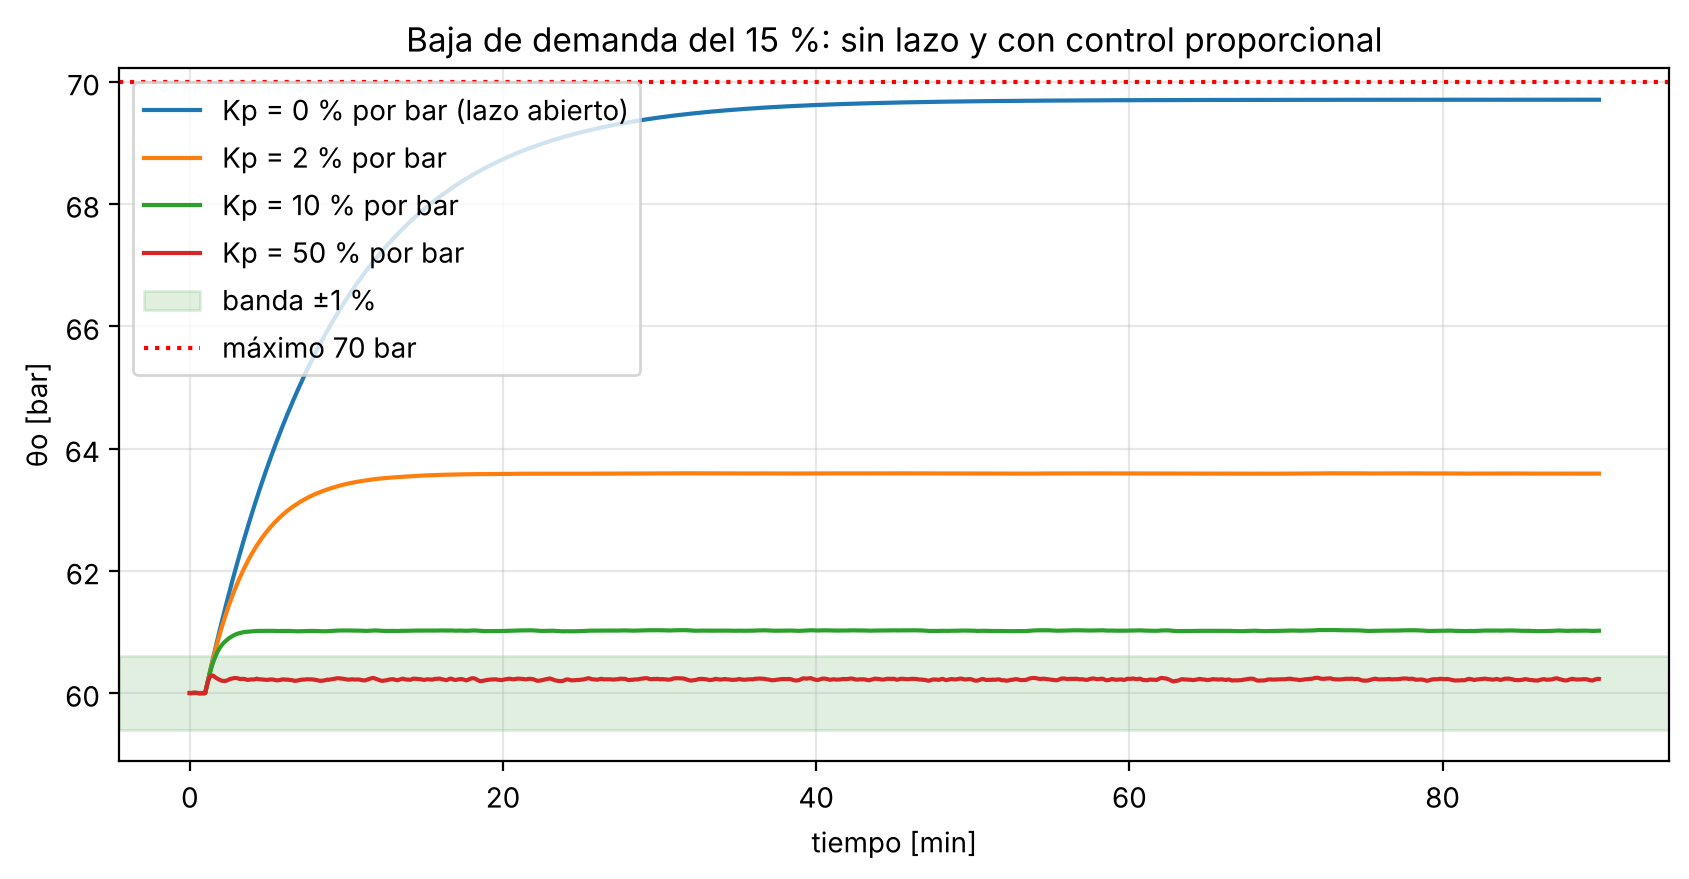

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for kp in (0.0, 2.0, 10.0, 50.0):
    r, q, _ = correr(kp=kp, ki=0.0, tipo="demanda", amp=15, t0=60, total=5400, supervision=False)
    ax.plot(r["t"] / 60, r["theta_o"], label=f"Kp = {kp:g} % por bar" + (" (lazo abierto)" if kp == 0 else ""))
    K = kp * K_B / (0.85 * K_OUT)
    print(f"Kp = {kp:5.1f}: presión final {r['theta_o'][-1]:6.2f} bar   (teoría con K = {K:4.1f}: {P_NOM + (0.15 / 0.85) * (P_NOM - P_SIG) / (1 + K):6.2f} bar)")
ax.axhspan(P_NOM * 0.99, P_NOM * 1.01, color="green", alpha=0.12, label="banda ±1 %")
ax.axhline(P_MAX, color="red", ls=":", label="máximo 70 bar")
ax.set_xlabel("tiempo [min]"); ax.set_ylabel("θo [bar]"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Baja de demanda del 15 %: sin lazo y con control proporcional")
plt.show()

## 5. Estabilidad: Routh-Hurwitz
Con P solo la ecuación característica es de tercer orden; con PI es de cuarto orden:

s·(τp·s + 1)(τv·s + 1)(τt·s + 1) + (K_B/k_out)·(Kp·s + Ki) = 0

In [5]:
def routh(coefs):
    filas = [list(coefs[0::2]), list(coefs[1::2])]
    ancho = max(len(f) for f in filas)
    filas = [f + [0.0] * (ancho - len(f)) for f in filas]
    while len(filas) < len(coefs):
        a, b = filas[-2], filas[-1]
        filas.append([(b[0] * a[i + 1] - a[0] * b[i + 1]) / b[0] if i + 1 < ancho else 0.0 for i in range(ancho)])
    return [f[0] for f in filas]

def caracteristica(kp, ki):
    p = np.polymul(np.polymul([tau_p, 1], [TAU_V, 1]), [TAU_T, 1])
    if ki == 0:
        return np.polyadd(p, [K_B / K_OUT * kp])
    return np.polyadd(np.polymul(p, [1, 0]), [K_B / K_OUT * kp, K_B / K_OUT * ki])

# P solo: ganancia crítica
t1, t2, t3 = tau_p, TAU_V, TAU_T
a3, a2, a1 = t1 * t2 * t3, t1 * t2 + t1 * t3 + t2 * t3, t1 + t2 + t3
k_crit = a2 * a1 / a3 - 1
print(f"P solo: estable si K < {k_crit:.0f}, es decir Kp < {k_crit * K_OUT / K_B:.0f} % por bar")

# PI elegido
col = routh(caracteristica(KP, KI))
raices = np.roots(caracteristica(KP, KI))
dom = raices[np.argmax(raices.real)]
print(f"PI (Kp = {KP:g}, Ki = {KI:g}): primera columna {'toda positiva, estable' if all(c > 0 for c in col) else 'con cambio de signo, inestable'}")
print(f"  polos dominantes: {dom.real/60:.2f} ± {abs(dom.imag)/60:.2f}j por minuto")

# Ki crítico con Kp = 10
for ki in np.arange(400, 10000, 10):
    if not all(c > 0 for c in routh(caracteristica(KP, ki))):
        print(f"Con Kp = {KP:g}, el lazo se vuelve inestable para Ki ≈ {ki:.0f} % por bar·h ({ki/60:.0f} % por bar·min)")
        break

P solo: estable si K < 476, es decir Kp < 658 % por bar
PI (Kp = 10, Ki = 400): primera columna toda positiva, estable
  polos dominantes: -0.64 ± 0.67j por minuto
Con Kp = 10, el lazo se vuelve inestable para Ki ≈ 3750 % por bar·h (62 % por bar·min)


## 6. Escenarios con todas las señales
Las nueve señales del lazo, una debajo de la otra, con el mismo eje de tiempo. La perturbación se aplica a los 90 s y los tiempos del registro se miden desde ese momento.

1. PI · baja la demanda 15 %
   00:42  θo sale de la banda (60.60 bar)
   02:04  vuelve a la banda en 82 s: transitoria, QoS cumplida


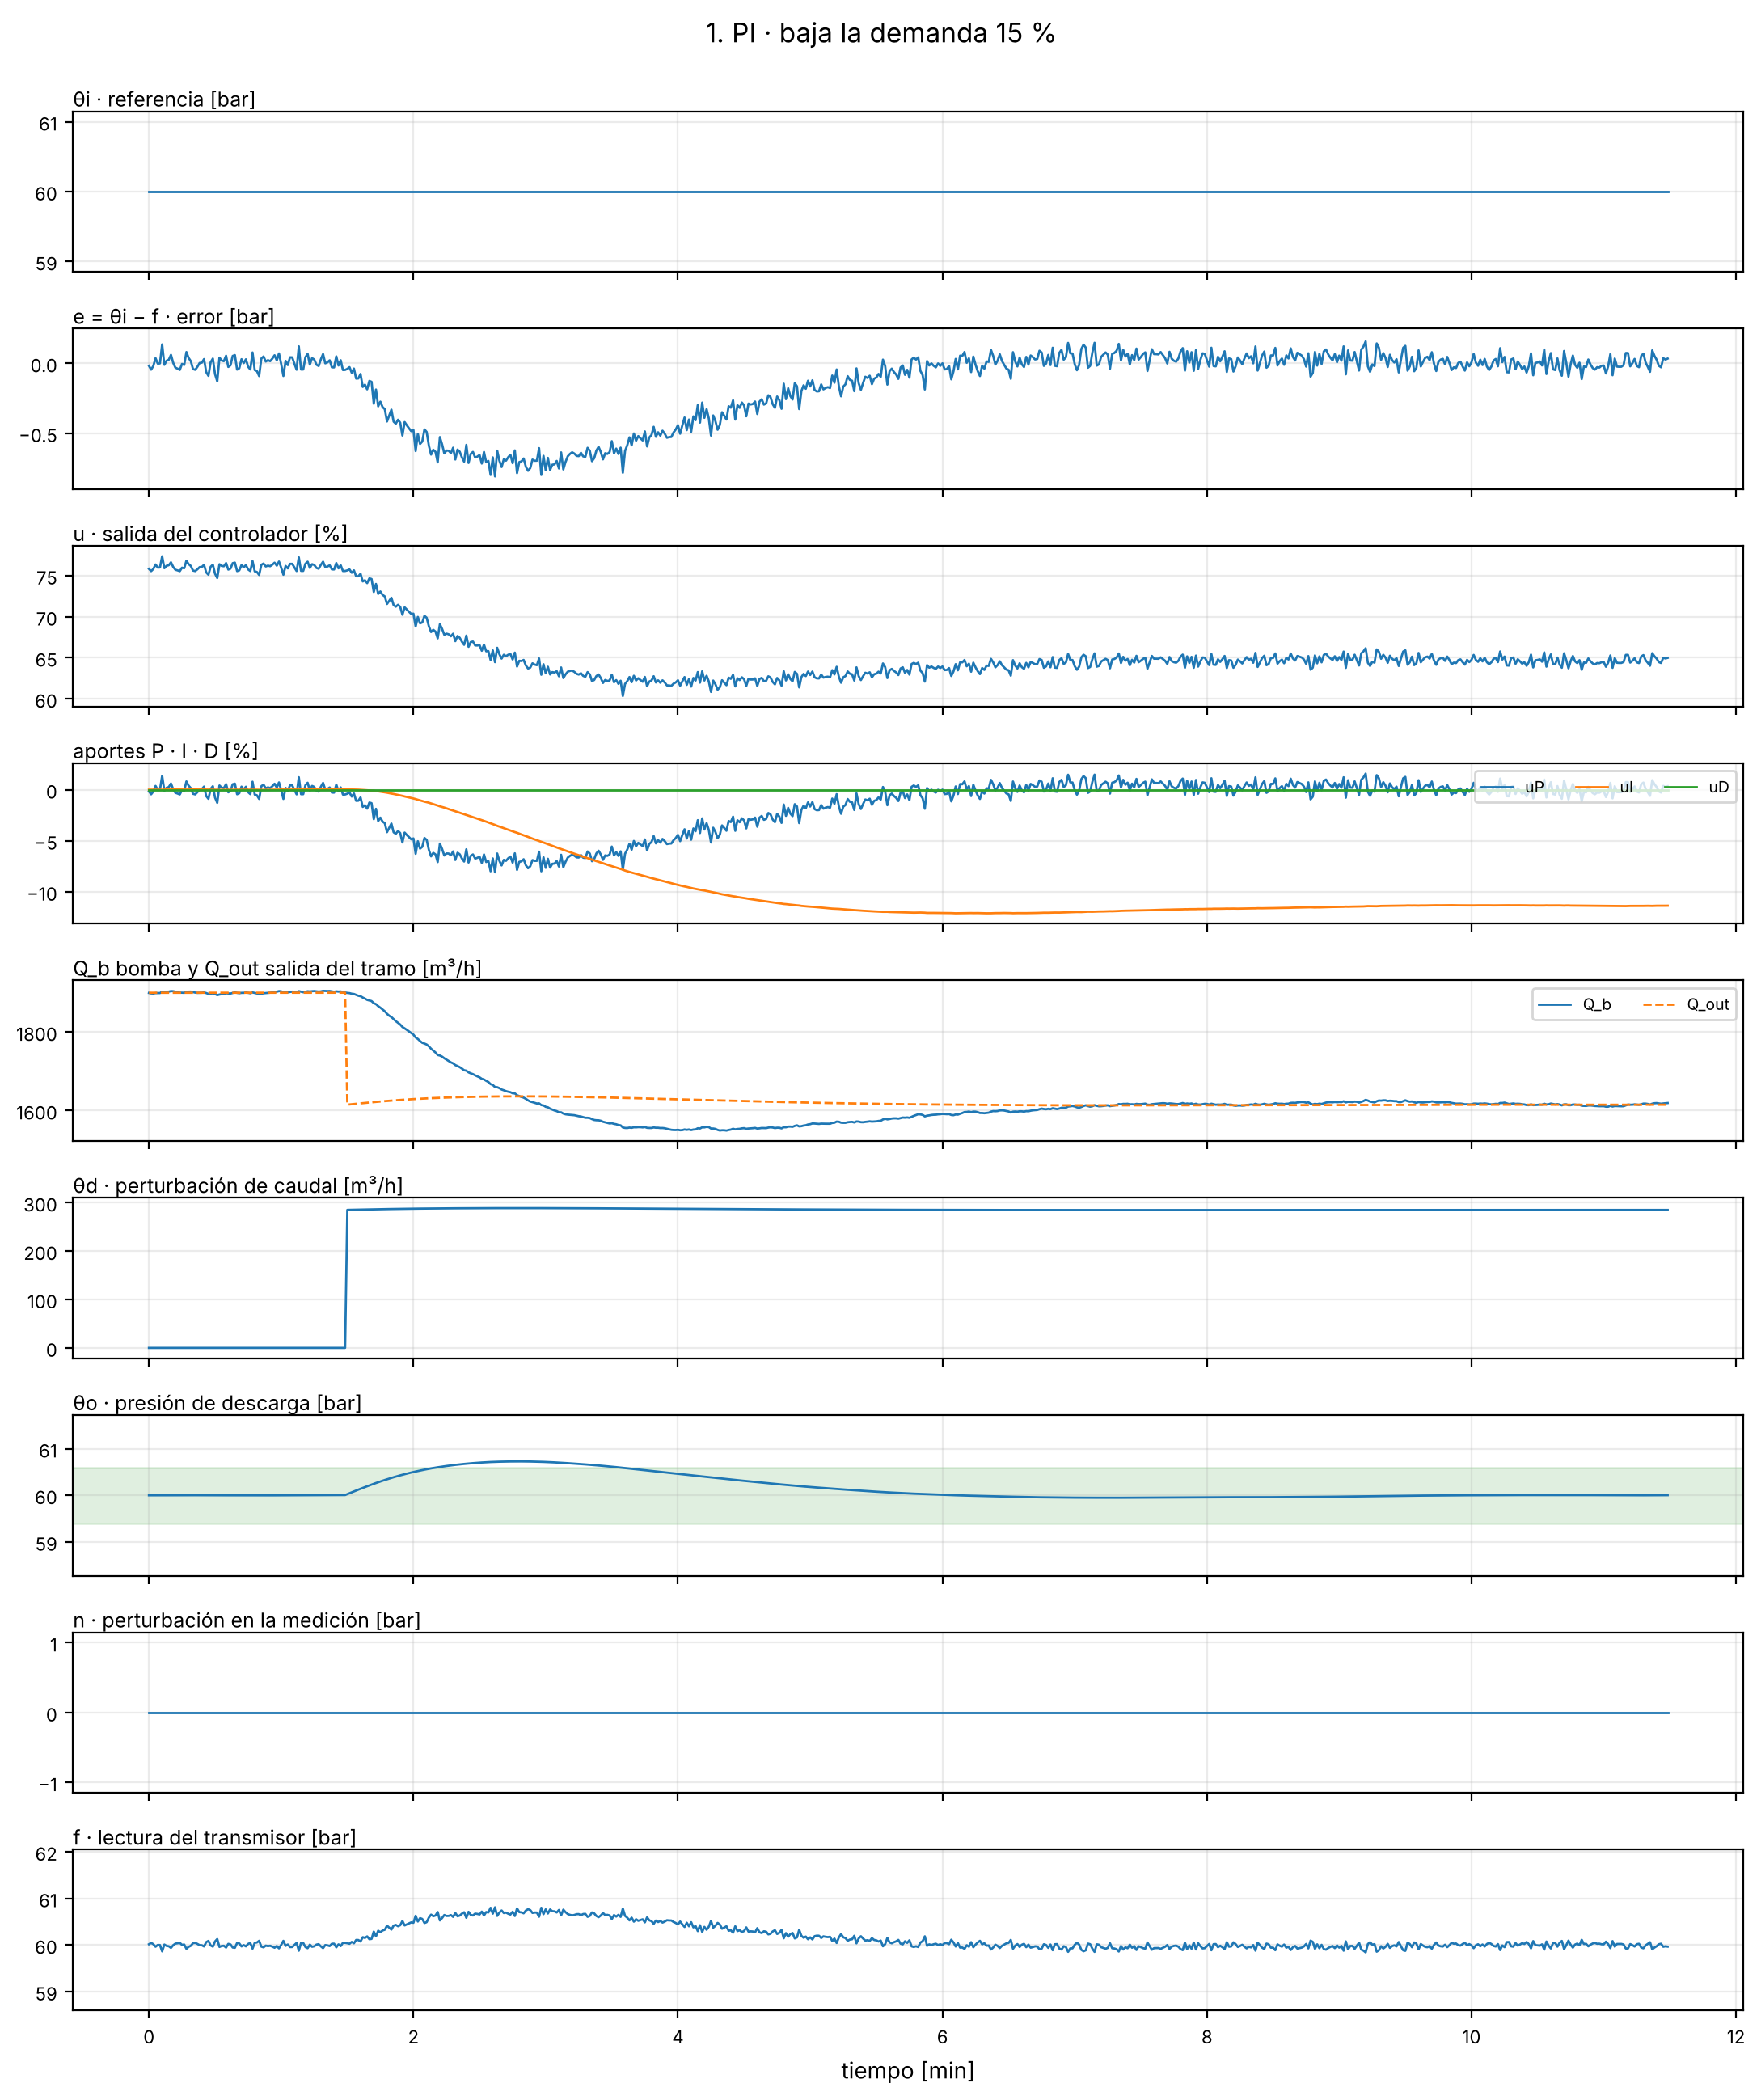

In [6]:
PANELES = [("θi · referencia [bar]", ["theta_i"]), ("e = θi − f · error [bar]", ["e"]),
           ("u · salida del controlador [%]", ["u"]), ("aportes P · I · D [%]", ["uP", "uI", "uD"]),
           ("Q_b bomba y Q_out salida del tramo [m³/h]", ["Q_b", "Q_out"]), ("θd · perturbación de caudal [m³/h]", ["theta_d"]),
           ("θo · presión de descarga [bar]", ["theta_o"]), ("n · perturbación en la medición [bar]", ["n"]),
           ("f · lectura del transmisor [bar]", ["f"])]
MIN_SPAN = [2, 1, 10, 4, 200, 100, 3, 2, 3]

def graficar(r, titulo="", vn=P_NOM, banda_pct=1.0, axs=None):
    if axs is None:
        fig, axs = plt.subplots(9, 1, figsize=(11, 13), sharex=True)
    t = r["t"] / 60
    for ax, (tit, keys), m in zip(axs, PANELES, MIN_SPAN):
        ax.clear()
        for k in keys:
            ax.plot(t, r[k], lw=1, ls="--" if k == "Q_out" else "-", label=k)
        vals = np.concatenate([r[k] for k in keys])
        lo, hi = vals.min(), vals.max()
        if keys == ["theta_o"]:
            b = vn * banda_pct / 100
            ax.axhspan(vn - b, vn + b, color="green", alpha=0.12)
            if hi > P_MAX - 2:
                ax.axhline(P_MAX, color="red", ls=":")
            lo, hi = min(lo, vn - 2 * b), max(hi, vn + 2 * b)
        c, sp = (lo + hi) / 2, max(hi - lo, m) * 1.15
        ax.set_ylim(c - sp / 2, c + sp / 2)
        ax.set_title(tit, fontsize=9, loc="left", pad=2)
        ax.tick_params(labelsize=8); ax.grid(alpha=0.25)
        if len(keys) > 1:
            ax.legend(fontsize=7, loc="upper right", ncol=3)
    axs[-1].set_xlabel("tiempo [min]")
    axs[0].figure.suptitle(titulo, y=0.995)
    axs[0].figure.tight_layout()
    return axs

ESCENARIOS = {
    "1. PI · baja la demanda 15 %":            dict(tipo="demanda", amp=15),
    "2. Solo P · misma baja":                  dict(ki=0, tipo="demanda", amp=15),
    "3. Solo P · baja de 60 s":                dict(ki=0, tipo="demanda", amp=15, dur=60),
    "4. PID · Kv = 5, sin perturbación":       dict(kv=5),
    "5. PI · Ki = 90 %/bar·min (sobre Routh)": dict(ki=90 * 60, tipo="demanda", amp=15, total=990),
    "6. Fuga de 200 m³/h":                     dict(tipo="fuga", amp=200, total=390),
    "7. Transmisor falseado −15 bar":          dict(tipo="medicion", amp=-15, total=690),
    # Cada acción por separado, con la misma baja de 15 % (40 minutos)
    "8. Sin control (lazo abierto)":           dict(kp=0, ki=0, tipo="demanda", amp=15, total=2400),
    "9. Solo I · misma baja":                  dict(kp=0, tipo="demanda", amp=15, total=2400),
    "10. Solo D · misma baja (Kv = 5)":        dict(kp=0, ki=0, kv=5, tipo="demanda", amp=15, total=2400),
}

def escenario(nombre):
    r, q, lazo = correr(**ESCENARIOS[nombre])
    print(nombre); print("\n".join("   " + ev for ev in q.eventos) or "   sin eventos")
    graficar(r, nombre); plt.show()

escenario("1. PI · baja la demanda 15 %")

2. Solo P · misma baja
   00:40  θo sale de la banda (60.60 bar)
   02:40  FALLA: más de 120 s fuera de banda


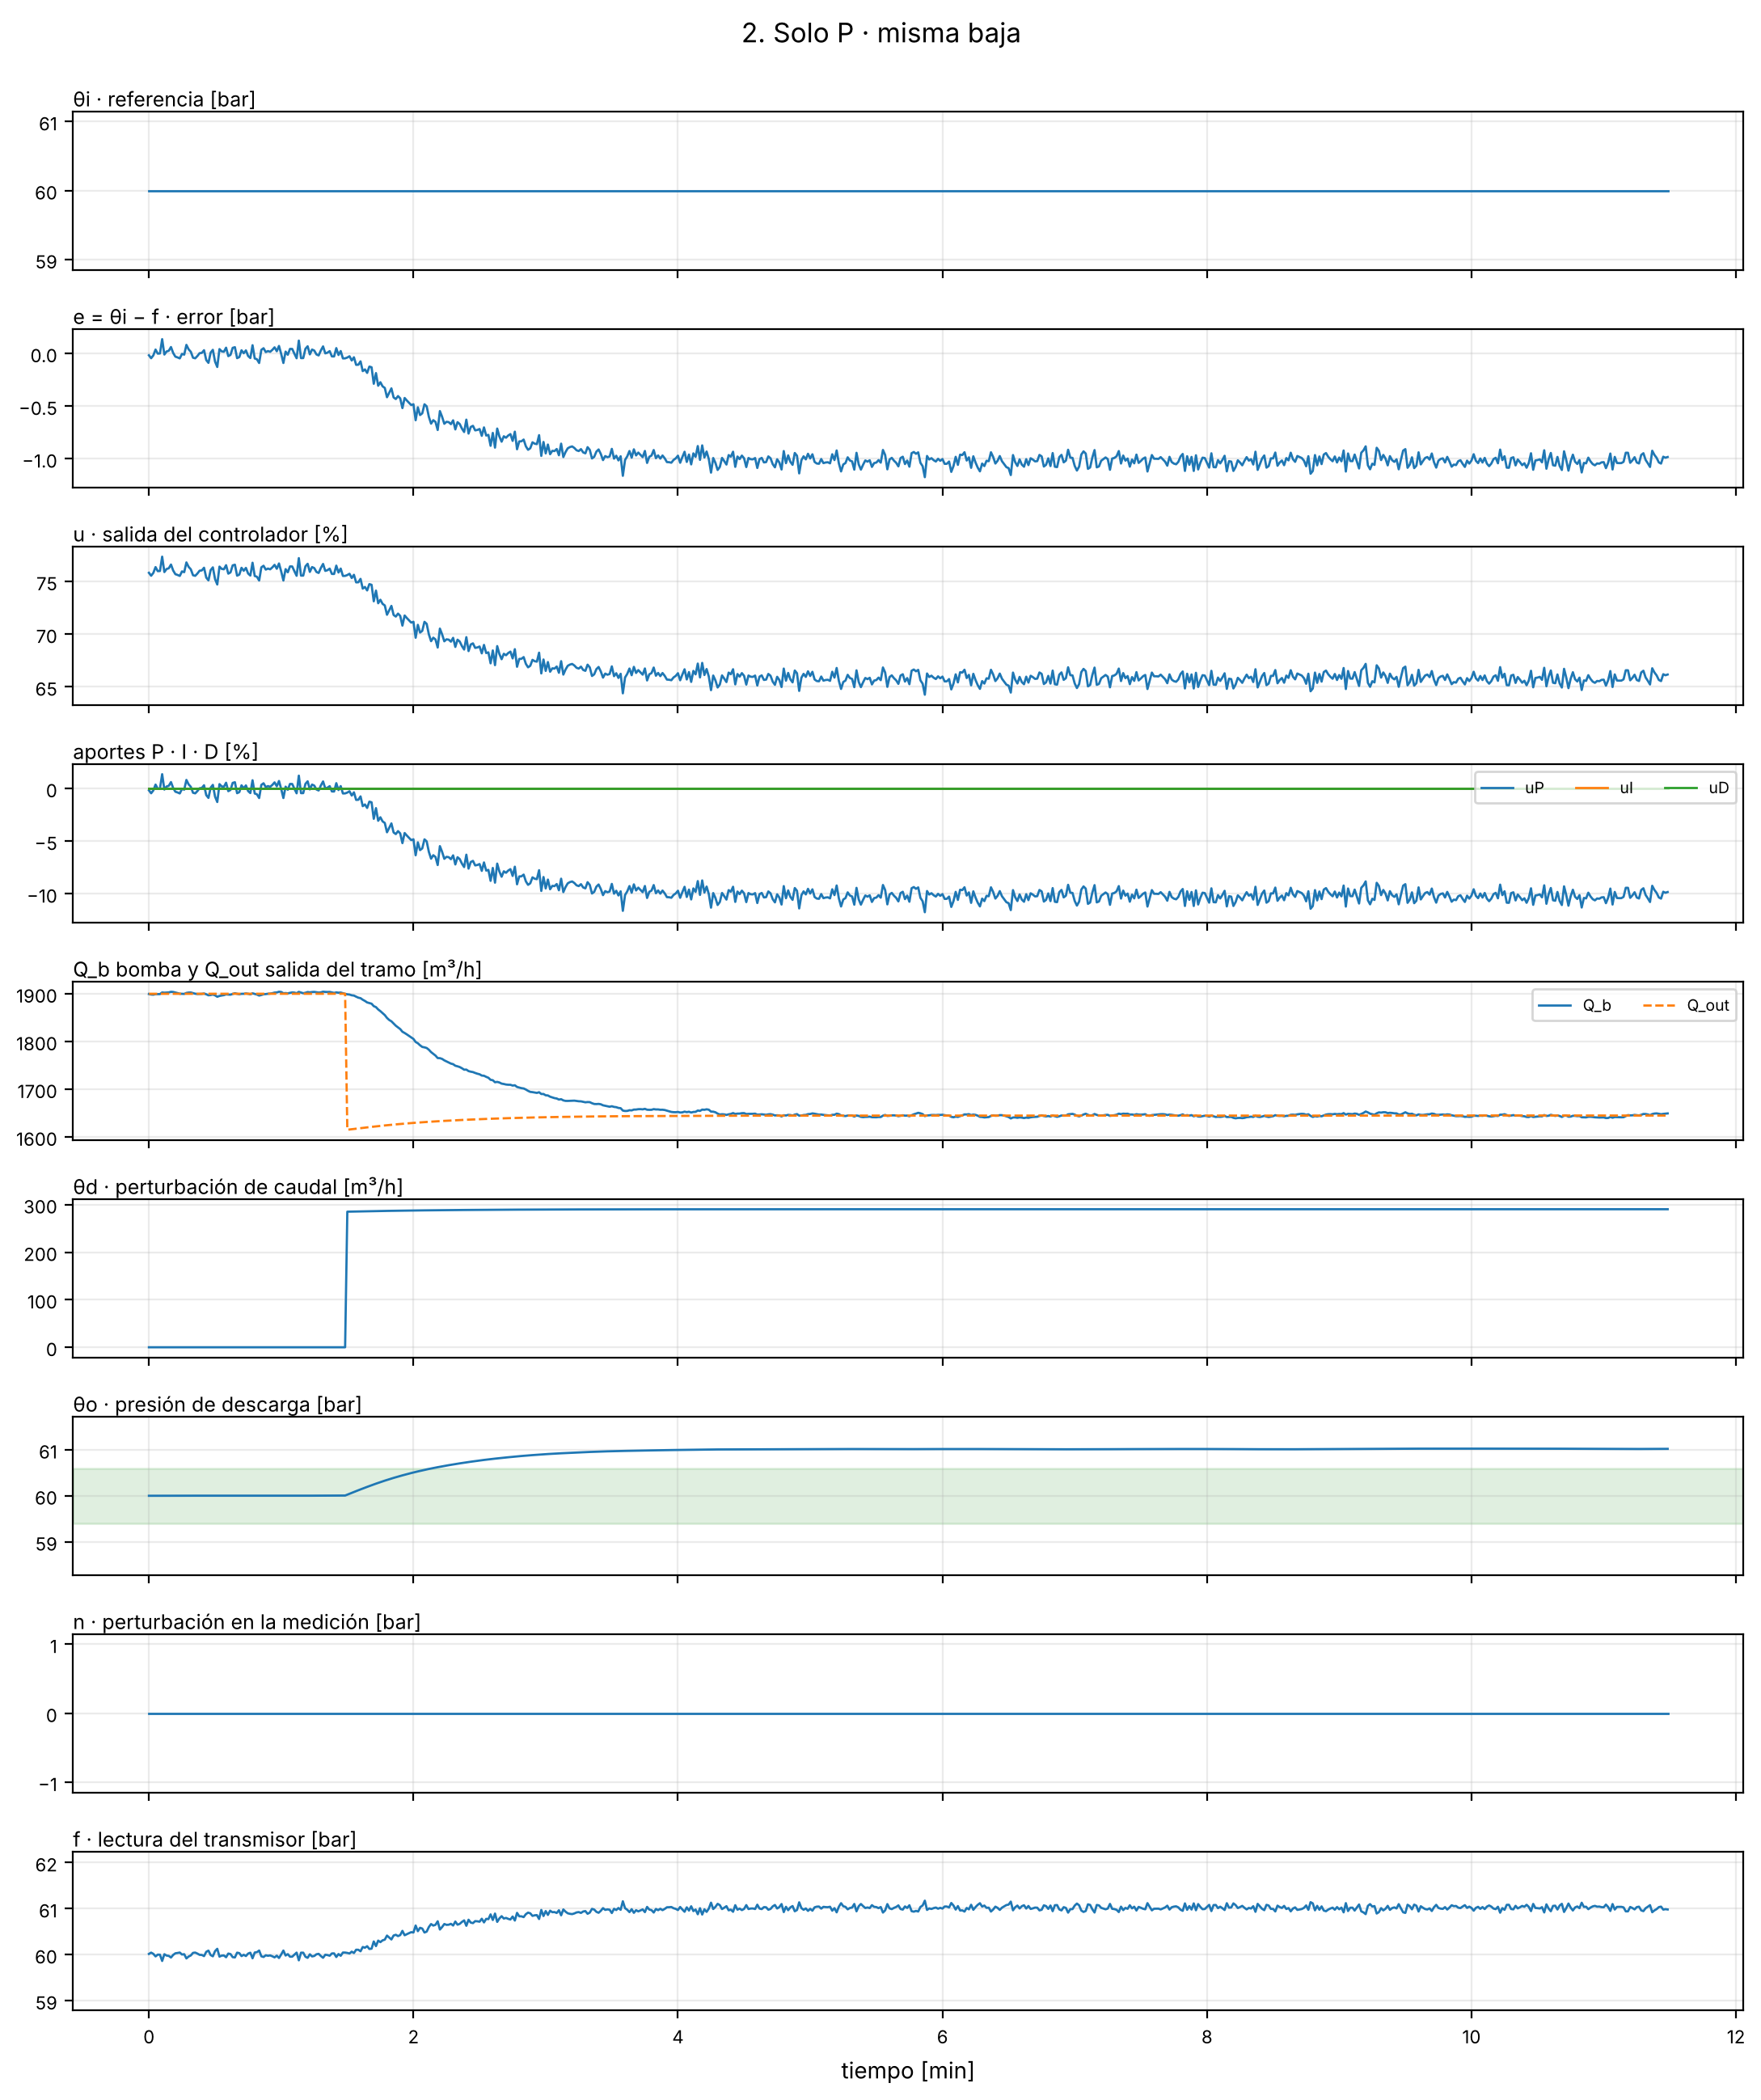

In [7]:
escenario("2. Solo P · misma baja")

3. Solo P · baja de 60 s
   00:40  θo sale de la banda (60.60 bar)
   01:12  vuelve a la banda en 32 s: transitoria, QoS cumplida


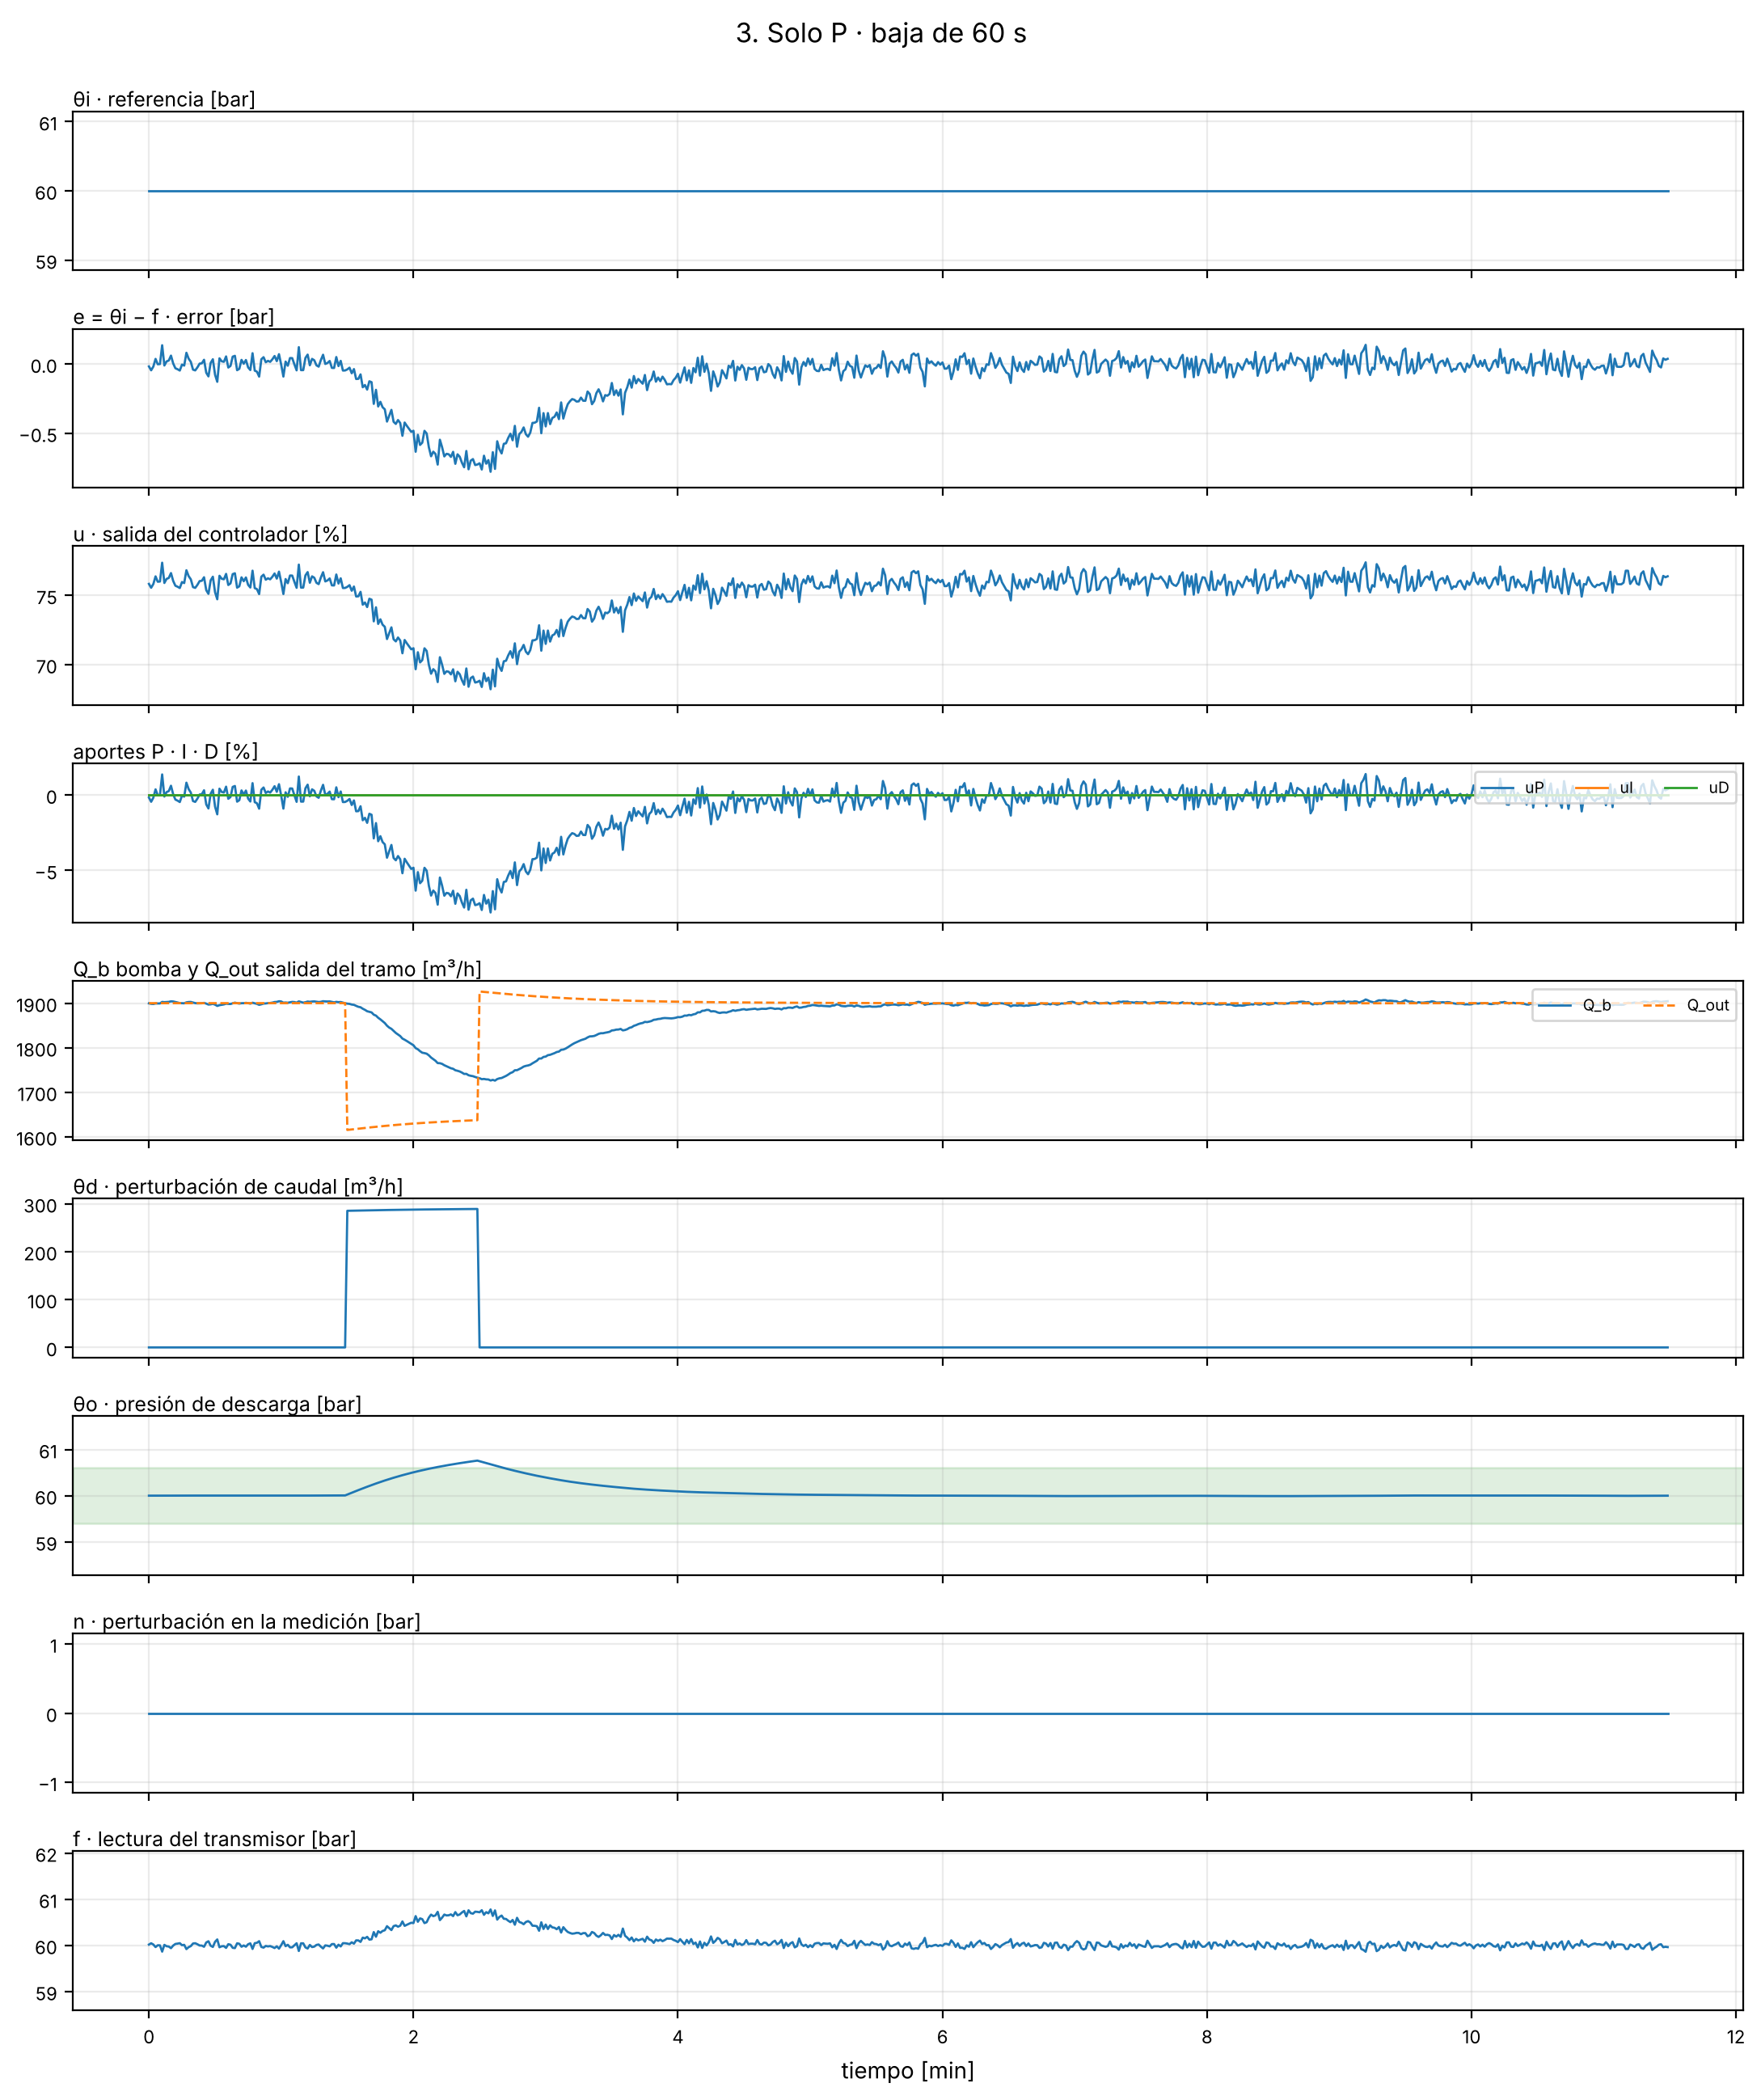

In [8]:
escenario("3. Solo P · baja de 60 s")

4. PID · Kv = 5, sin perturbación
   sin eventos


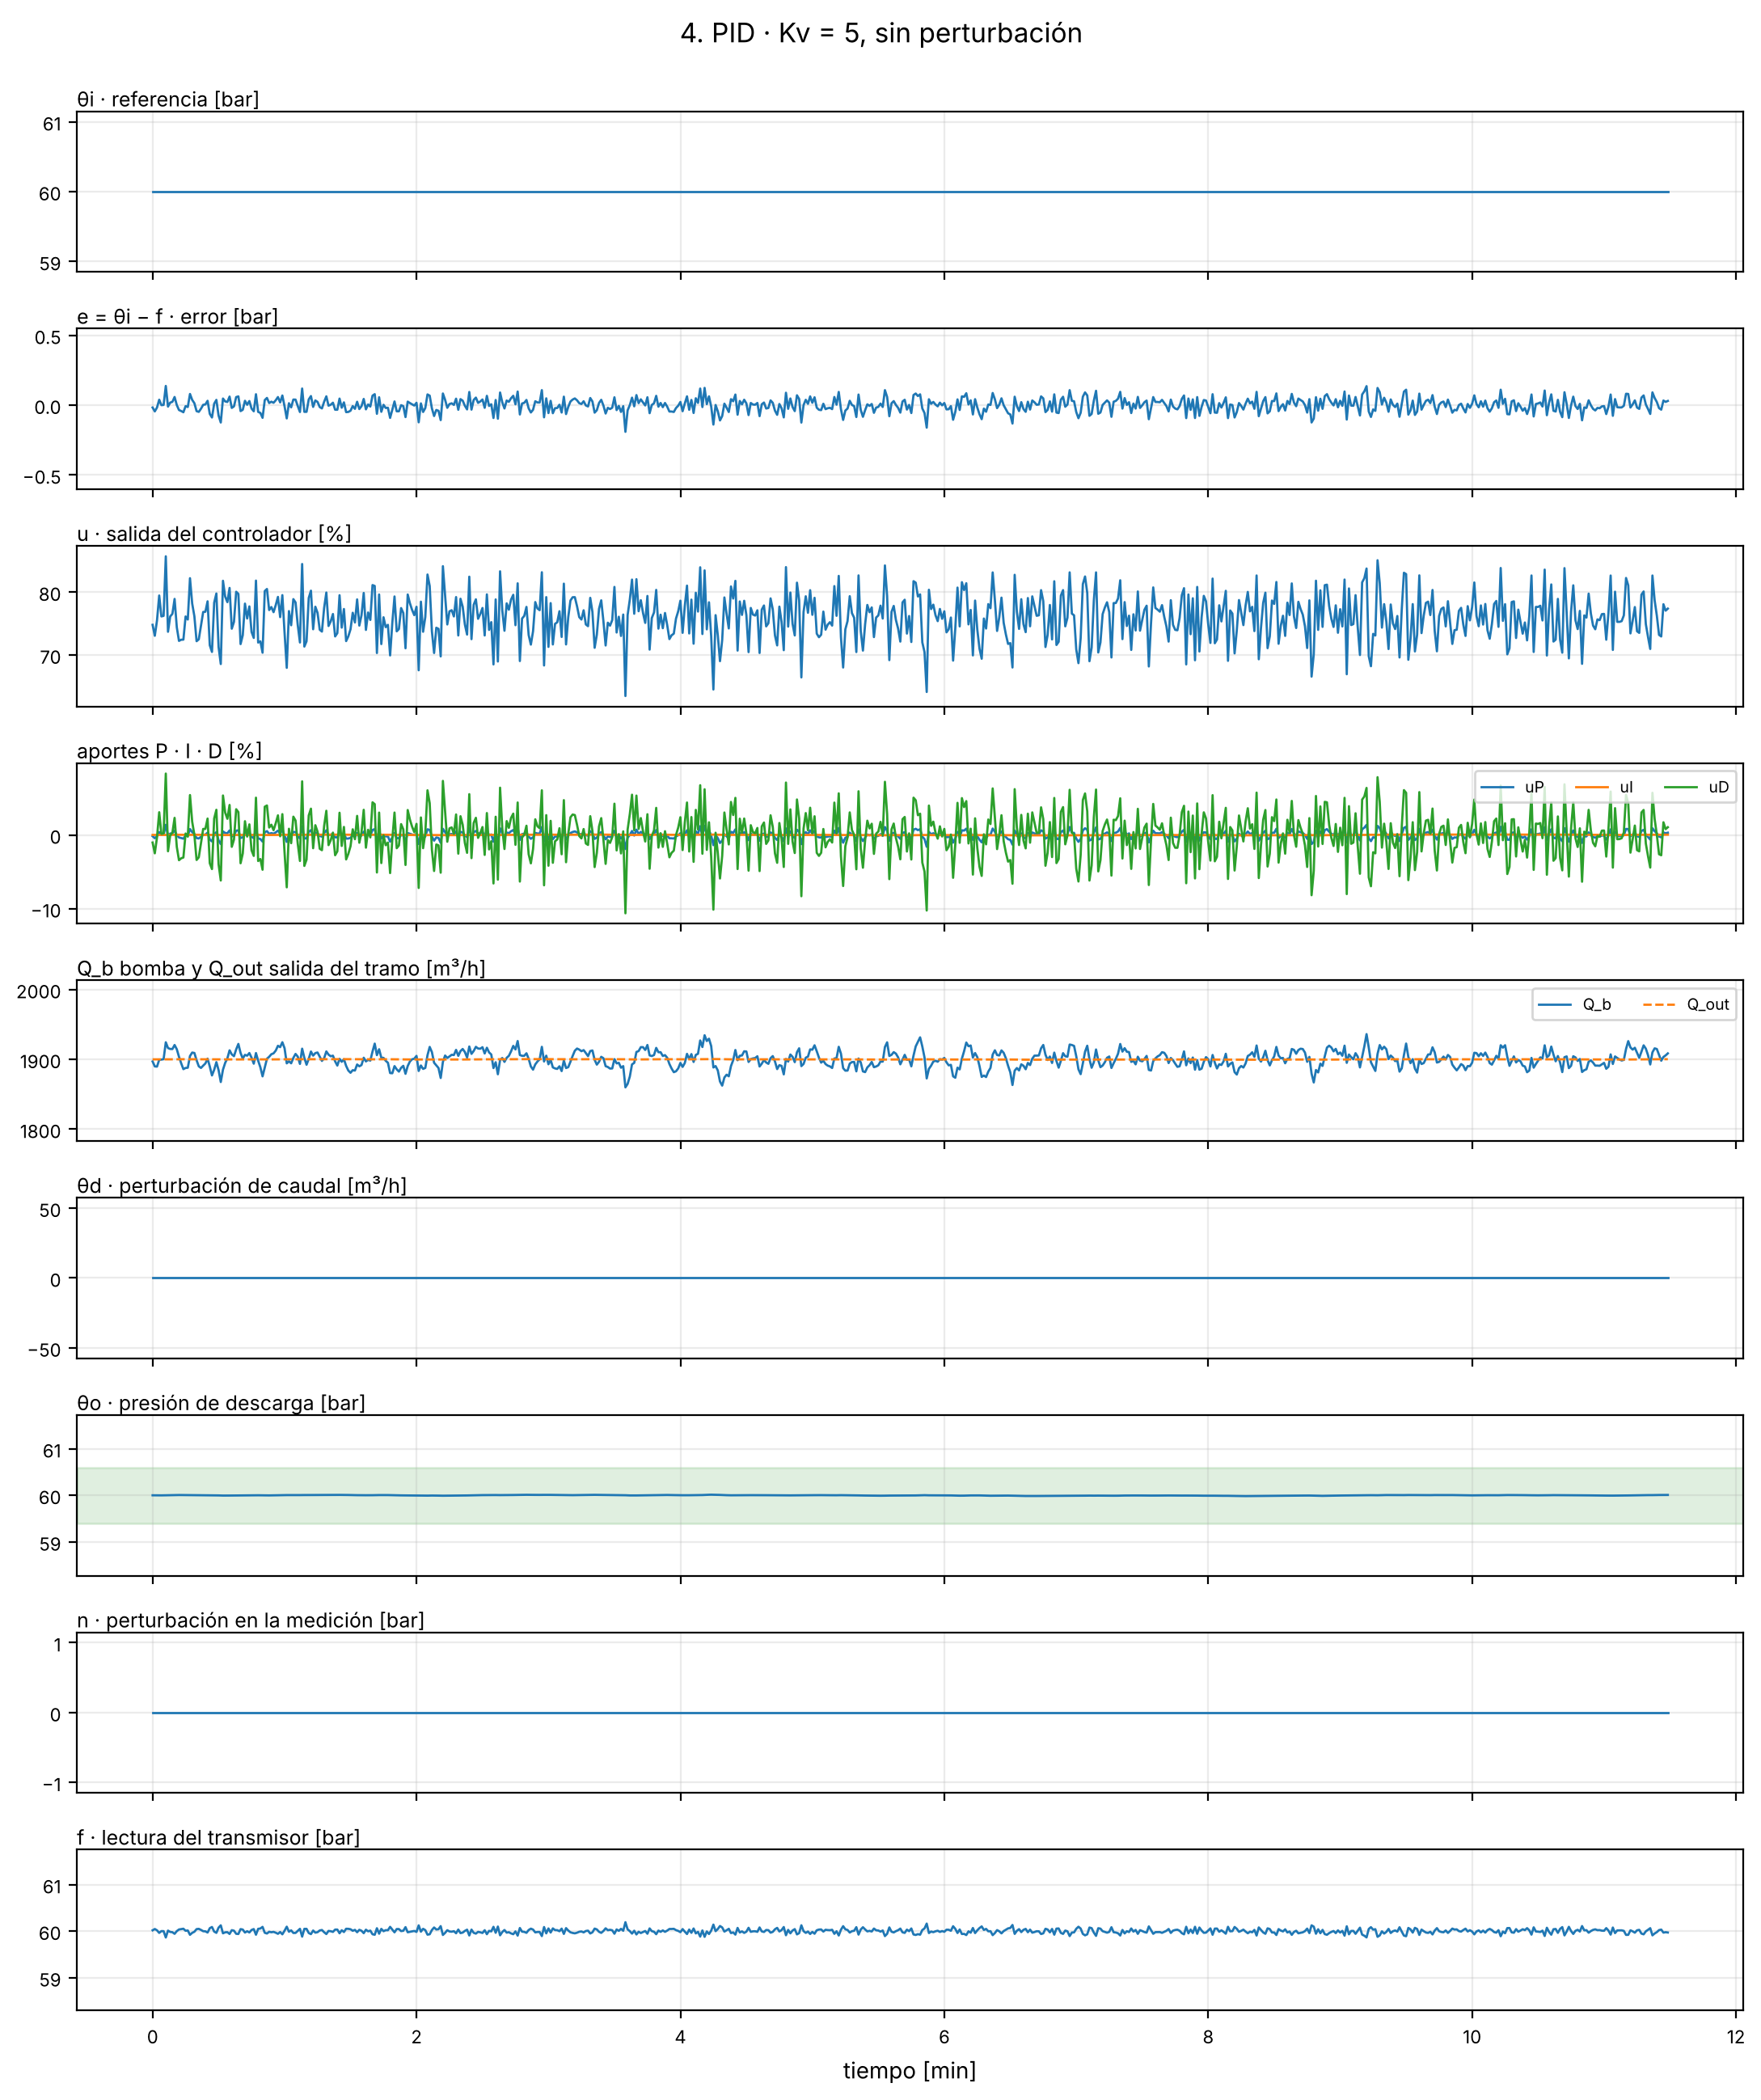

In [9]:
escenario("4. PID · Kv = 5, sin perturbación")

5. PI · Ki = 90 %/bar·min (sobre Routh)
   03:35  θo sale de la banda (59.40 bar)
   03:50  vuelve a la banda en 15 s: transitoria, QoS cumplida
   04:34  θo sale de la banda (60.61 bar)
   04:59  vuelve a la banda en 25 s: transitoria, QoS cumplida
   05:33  θo sale de la banda (59.40 bar)
   06:07  vuelve a la banda en 34 s: transitoria, QoS cumplida
   06:35  θo sale de la banda (60.62 bar)
   07:13  vuelve a la banda en 38 s: transitoria, QoS cumplida
   07:36  θo sale de la banda (59.39 bar)
   08:18  vuelve a la banda en 42 s: transitoria, QoS cumplida
   08:41  θo sale de la banda (60.65 bar)
   09:23  vuelve a la banda en 42 s: transitoria, QoS cumplida
   09:42  θo sale de la banda (59.40 bar)
   10:29  vuelve a la banda en 47 s: transitoria, QoS cumplida
   10:51  θo sale de la banda (60.62 bar)
   11:33  vuelve a la banda en 42 s: transitoria, QoS cumplida
   11:53  θo sale de la banda (59.37 bar)
   12:39  vuelve a la banda en 46 s: transitoria, QoS cumplida
   13:01  θo sa

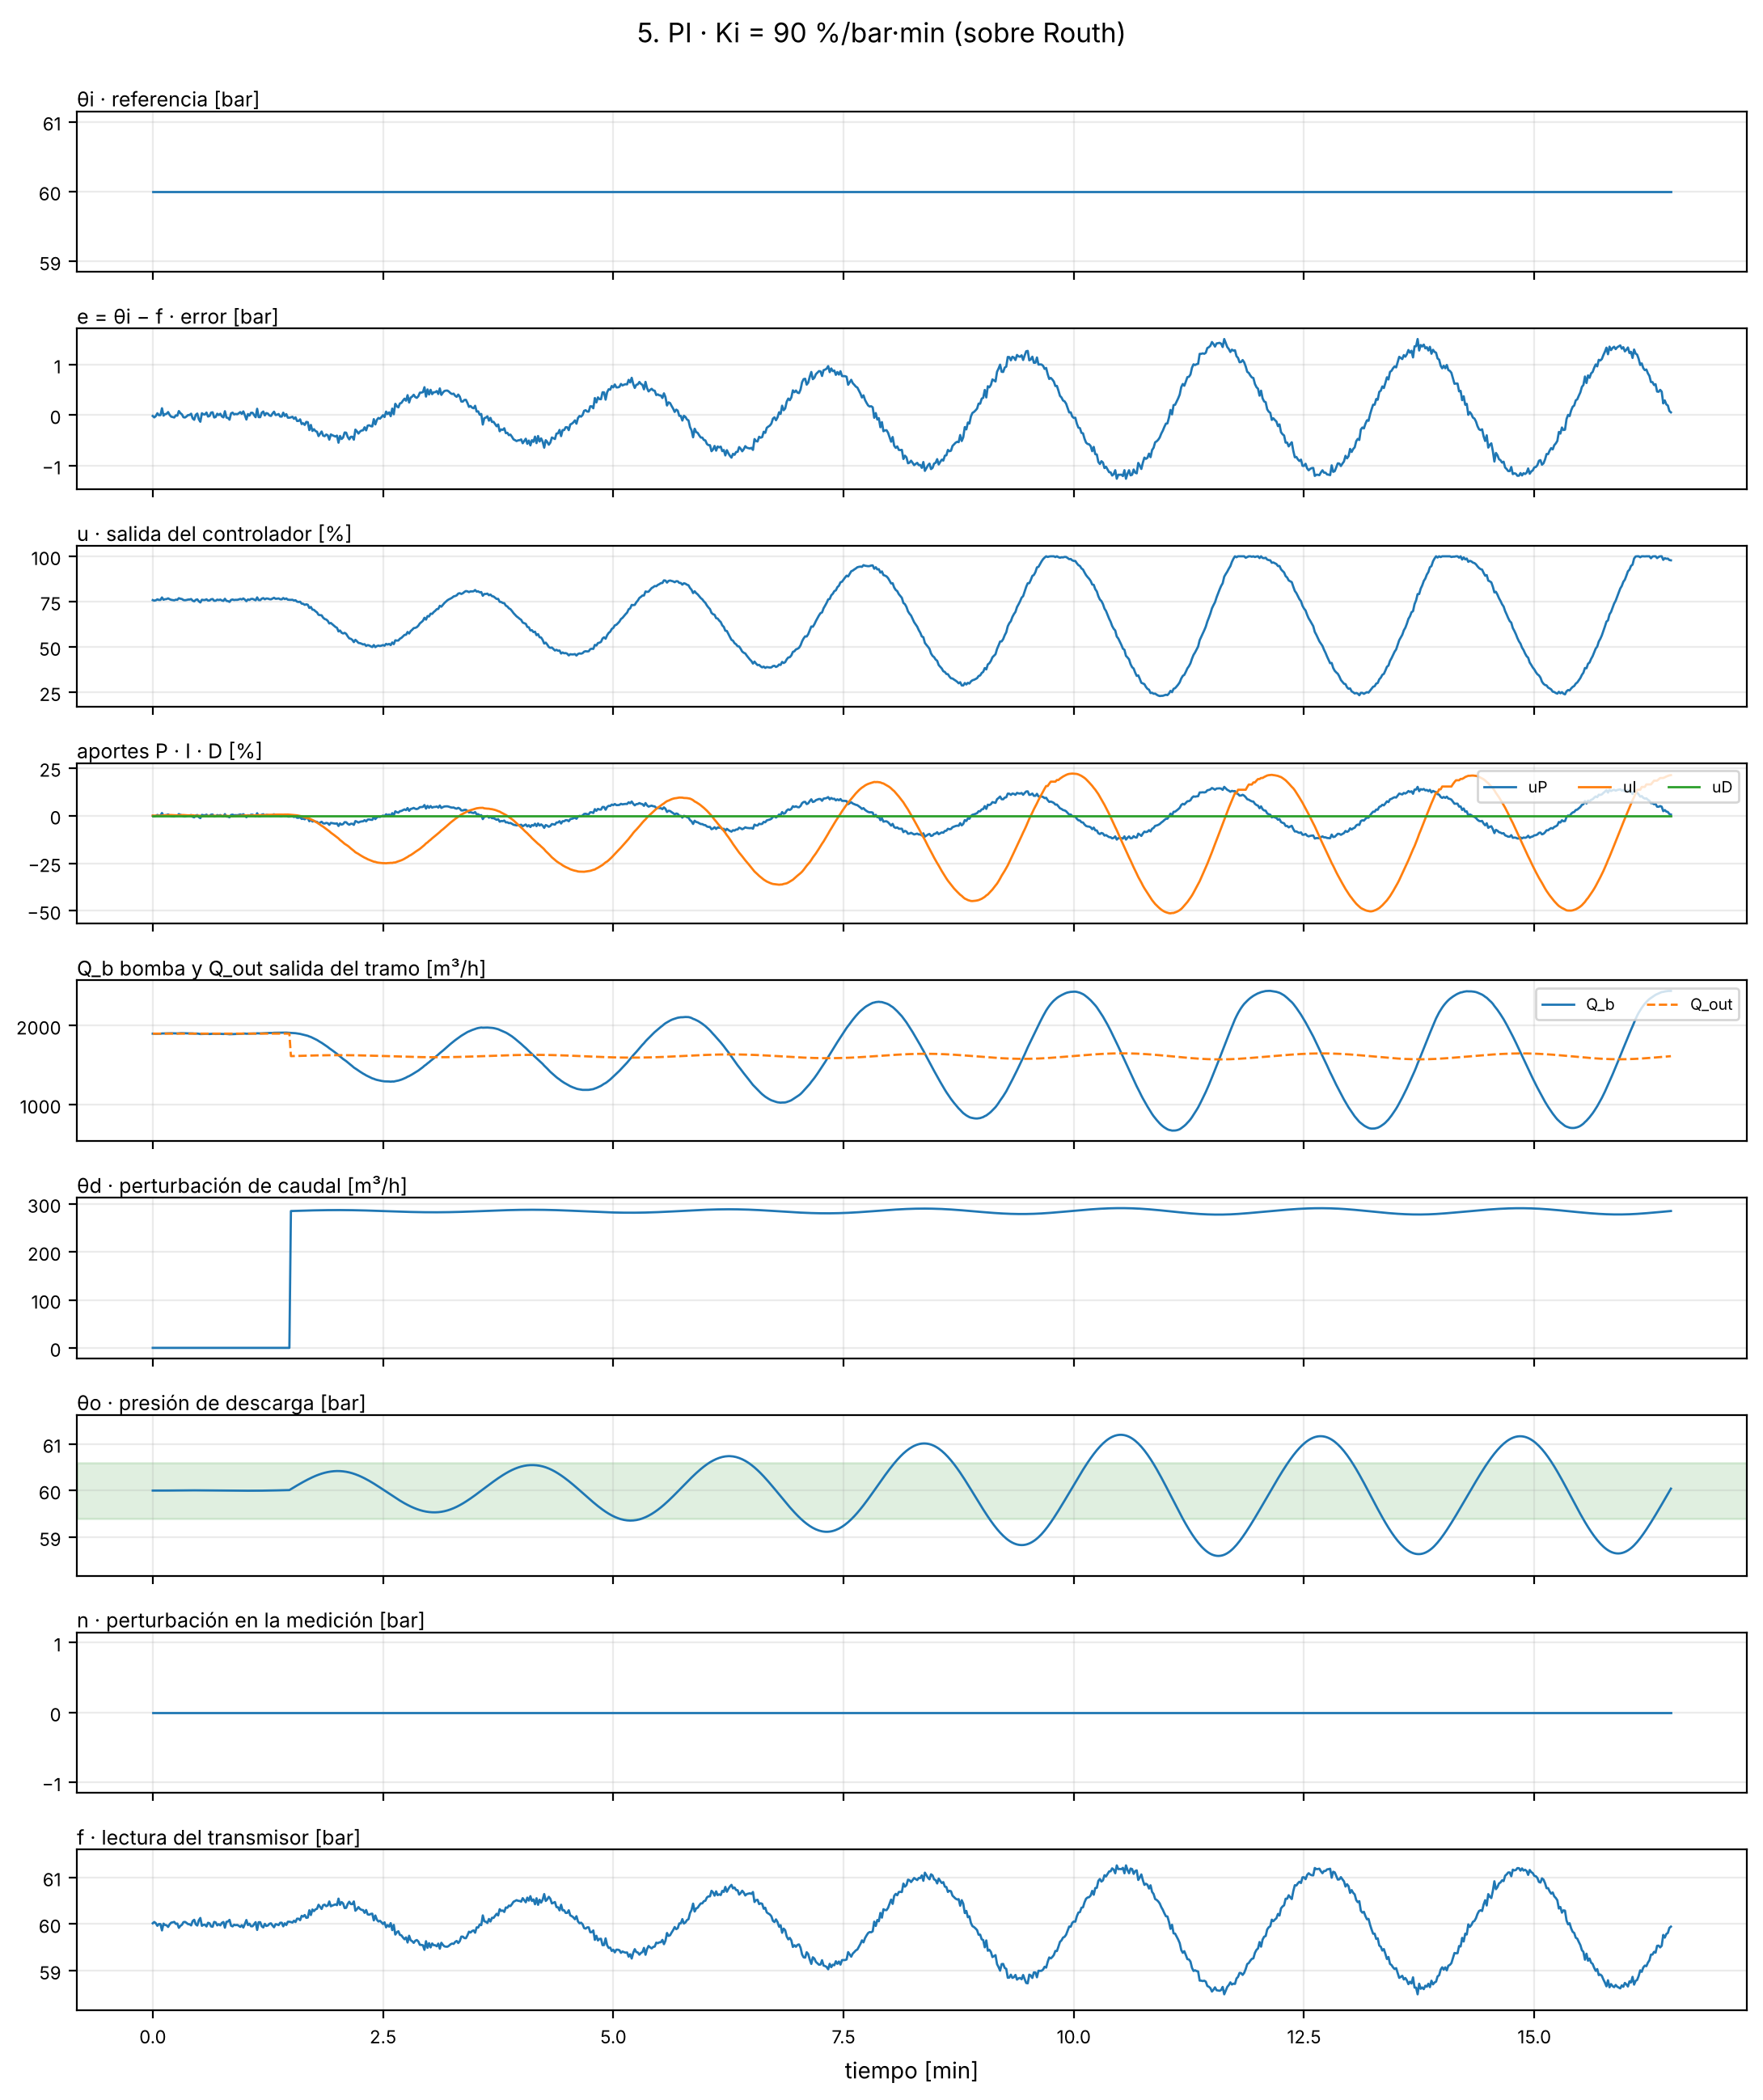

In [10]:
escenario("5. PI · Ki = 90 %/bar·min (sobre Routh)")

6. Fuga de 200 m³/h
   00:16  PARADA por fuga
   00:26  θo sale de la banda (59.36 bar)
   02:26  FALLA: más de 120 s fuera de banda


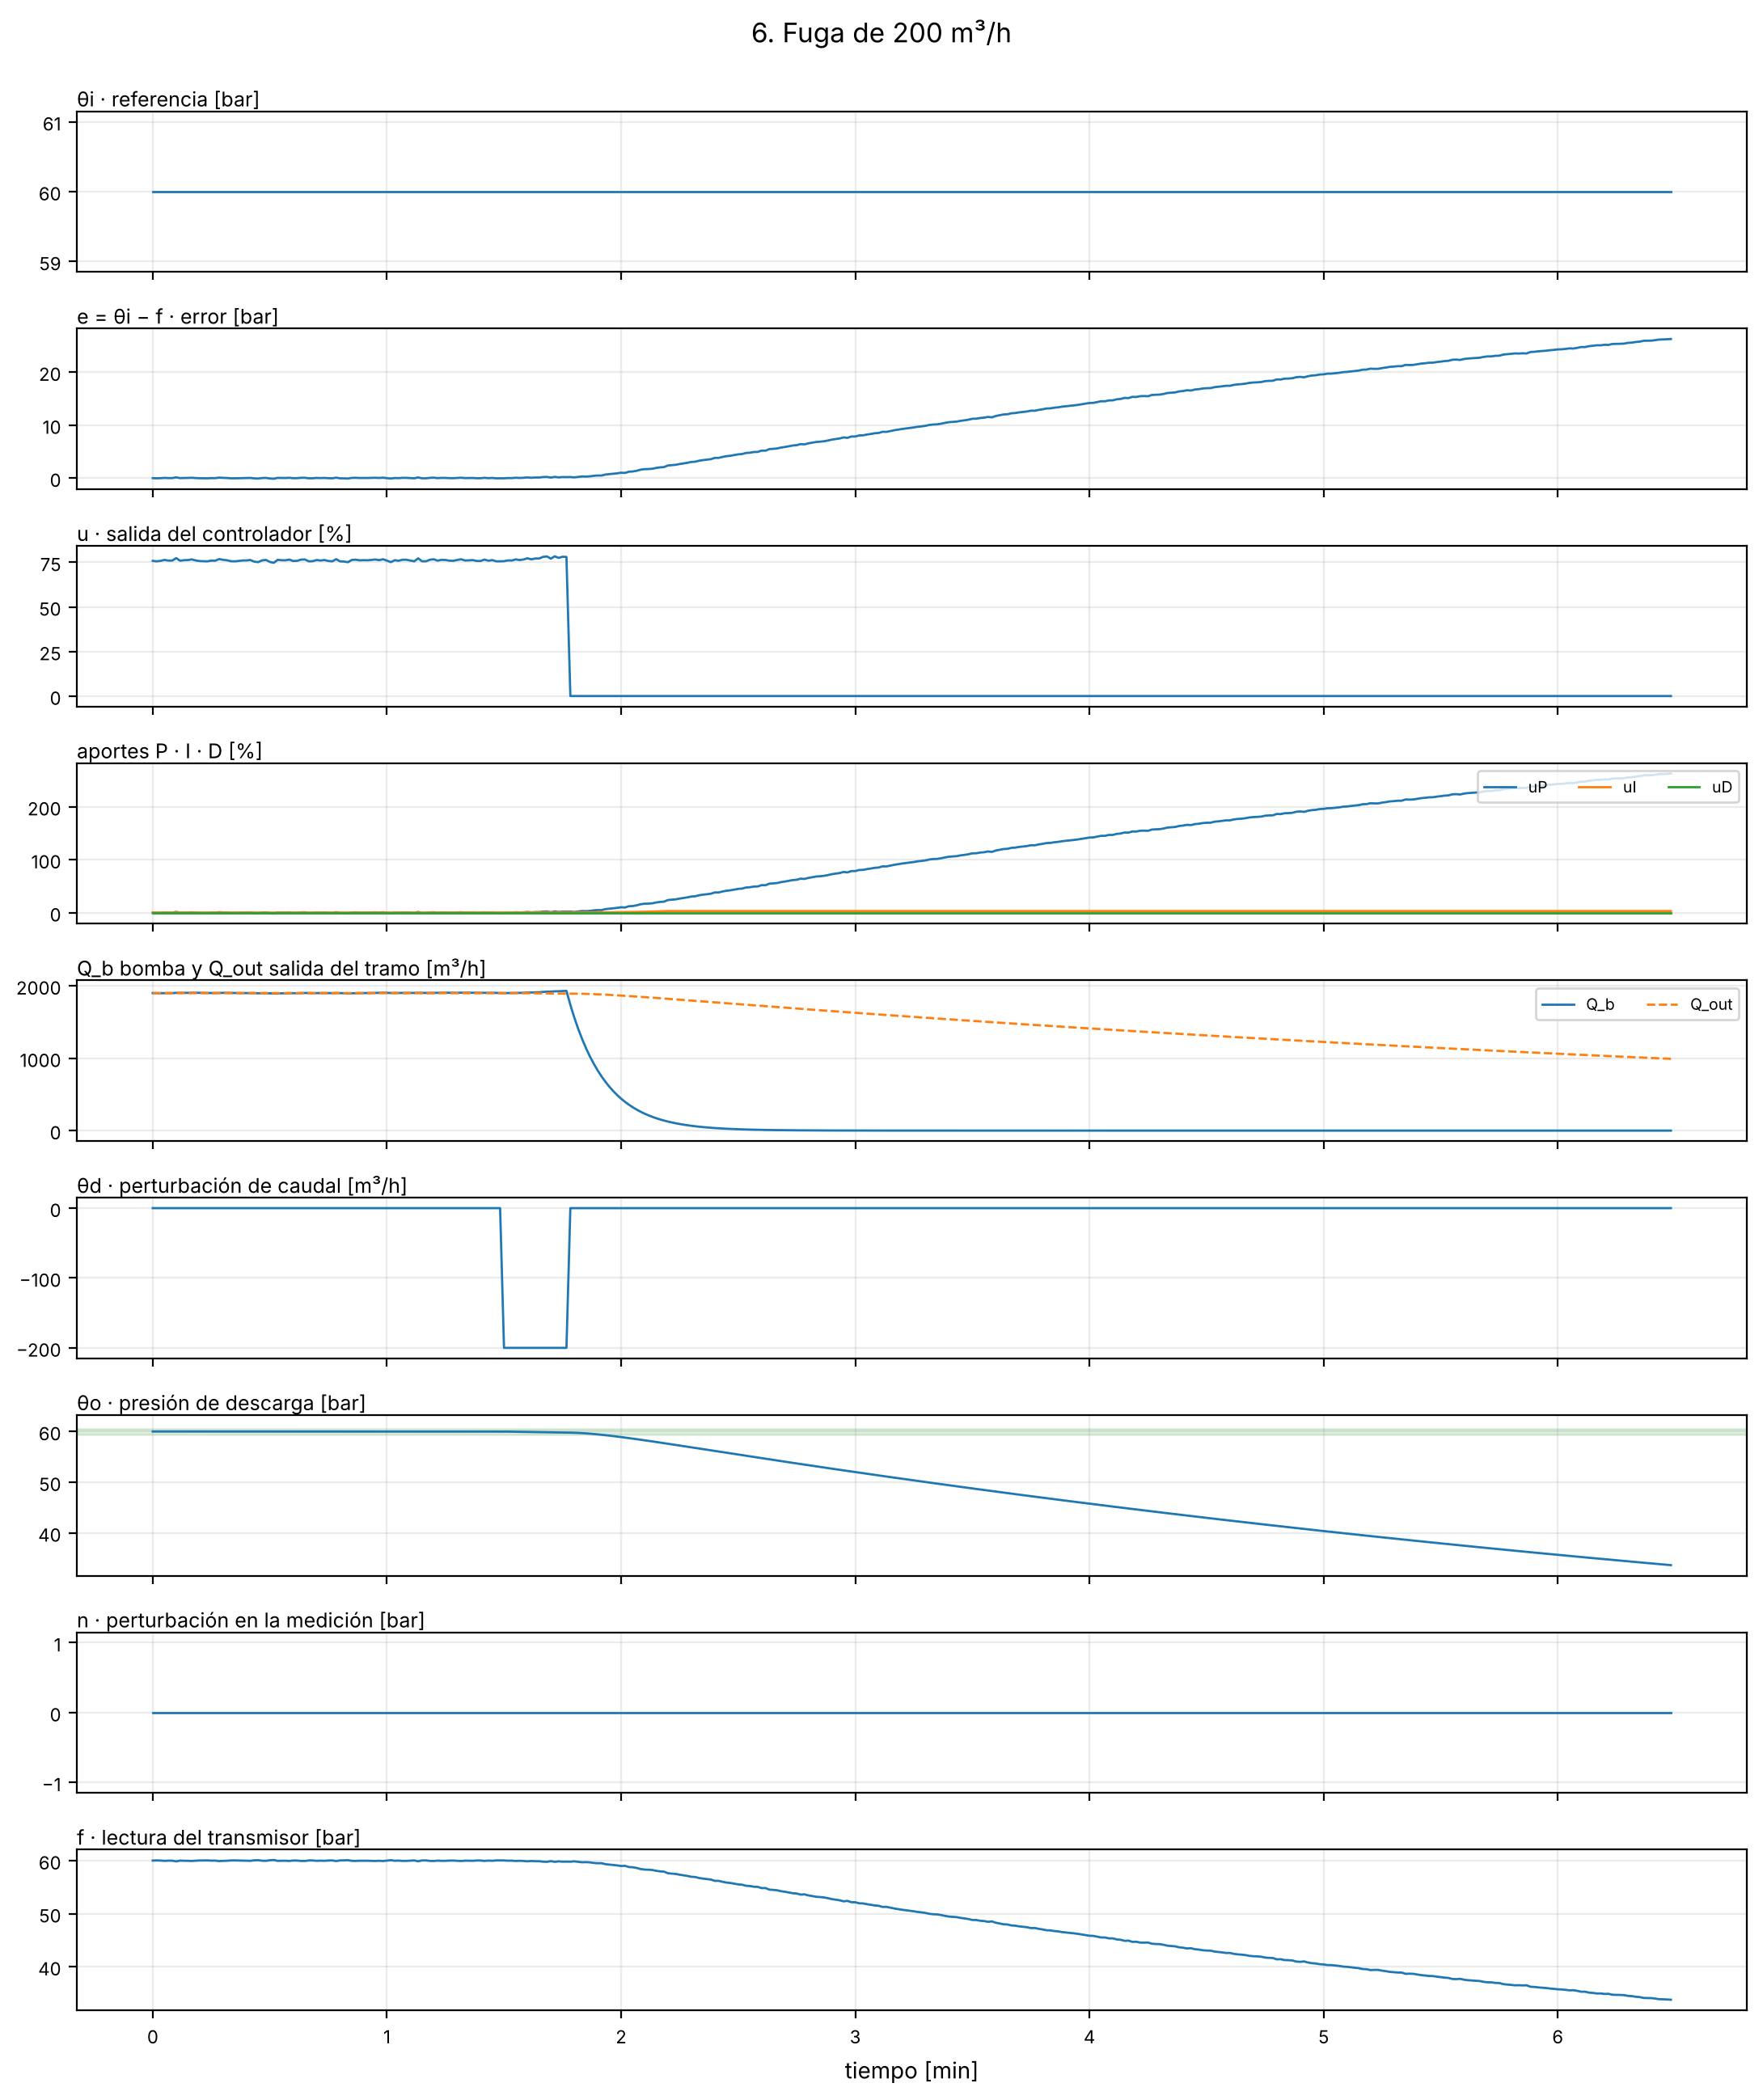

In [11]:
escenario("6. Fuga de 200 m³/h")

7. Transmisor falseado −15 bar
   00:23  θo sale de la banda (60.60 bar)
   02:23  FALLA: más de 120 s fuera de banda
   06:10  PARADA por alta presión
   07:28  vuelve a la banda en 425 s (falla registrada)
   07:37  θo sale de la banda (59.30 bar)
   09:37  FALLA: más de 120 s fuera de banda


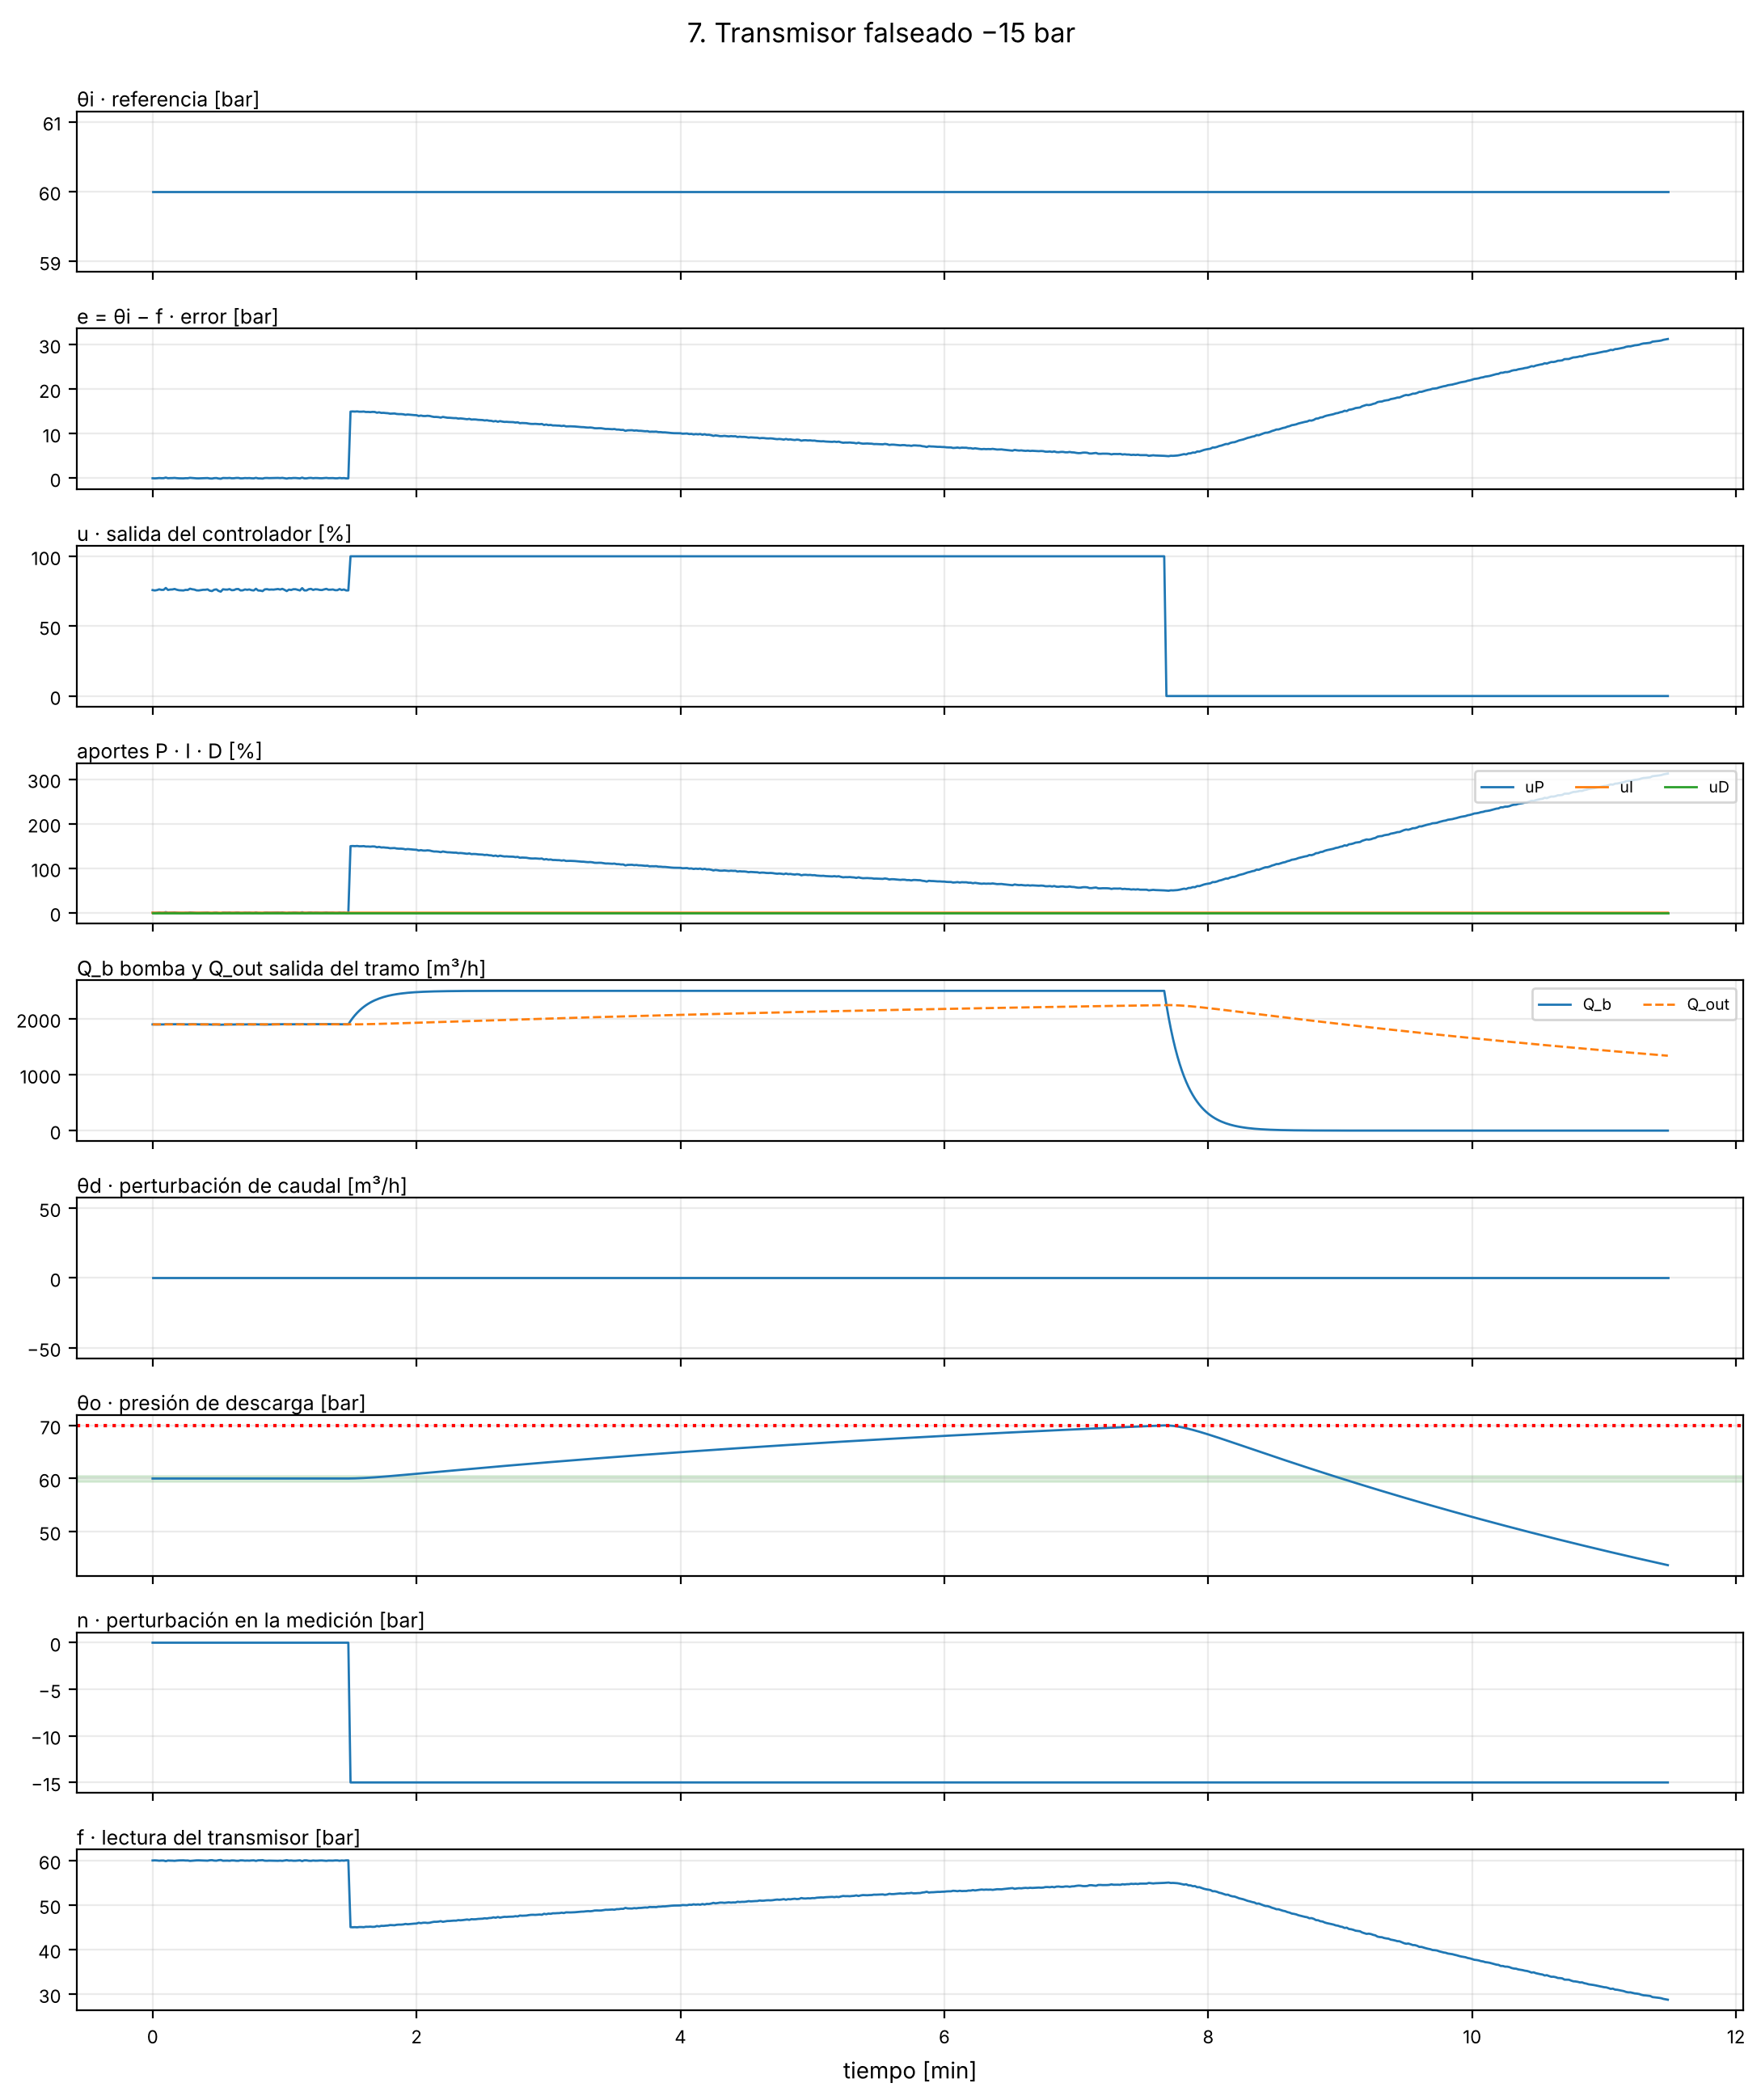

In [12]:
escenario("7. Transmisor falseado −15 bar")

8. Sin control (lazo abierto)
   00:32  θo sale de la banda (60.61 bar)
   02:32  FALLA: más de 120 s fuera de banda


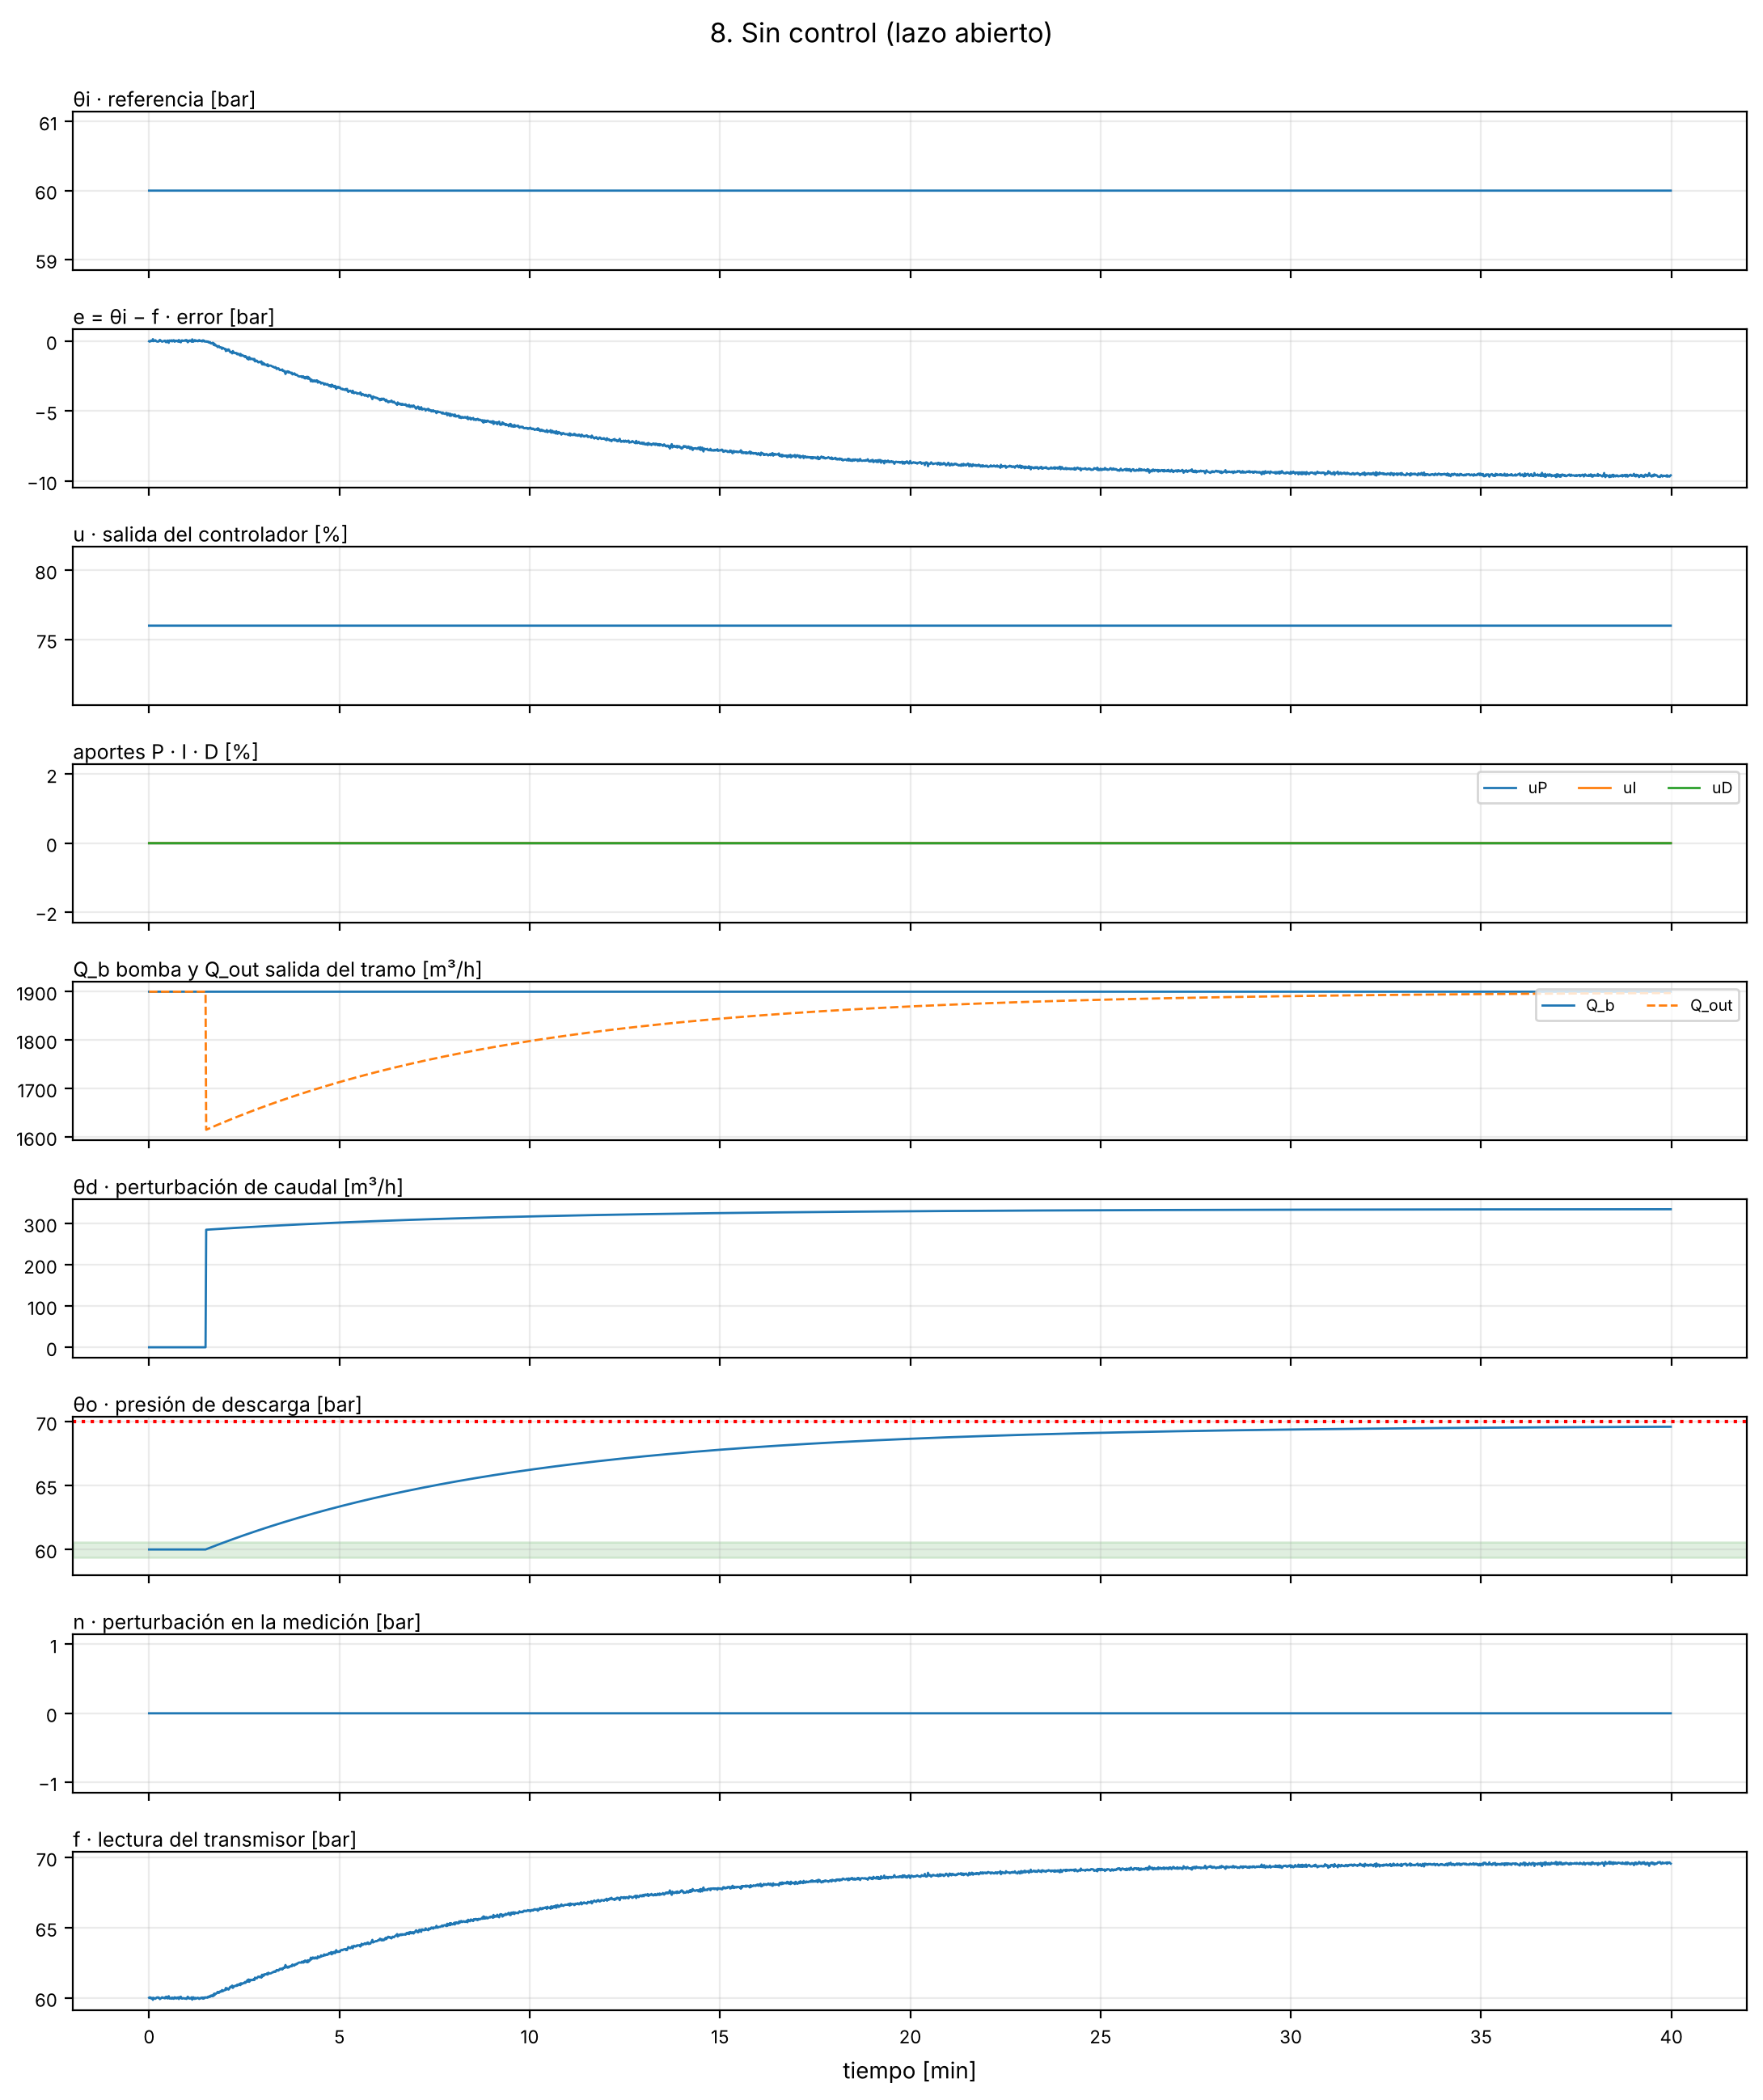

In [13]:
escenario("8. Sin control (lazo abierto)")

9. Solo I · misma baja
   00:33  θo sale de la banda (60.62 bar)
   02:33  FALLA: más de 120 s fuera de banda
   03:18  vuelve a la banda en 165 s (falla registrada)
   04:23  θo sale de la banda (59.39 bar)
   06:23  FALLA: más de 120 s fuera de banda
   07:07  vuelve a la banda en 164 s (falla registrada)
   08:14  θo sale de la banda (60.61 bar)
   10:14  FALLA: más de 120 s fuera de banda
   10:57  vuelve a la banda en 163 s (falla registrada)
   12:04  θo sale de la banda (59.38 bar)
   14:04  FALLA: más de 120 s fuera de banda
   14:45  vuelve a la banda en 161 s (falla registrada)
   15:53  θo sale de la banda (60.60 bar)
   17:53  FALLA: más de 120 s fuera de banda
   18:34  vuelve a la banda en 161 s (falla registrada)
   19:43  θo sale de la banda (59.39 bar)
   21:43  FALLA: más de 120 s fuera de banda
   22:23  vuelve a la banda en 160 s (falla registrada)
   23:34  θo sale de la banda (60.60 bar)
   25:34  FALLA: más de 120 s fuera de banda
   26:12  vuelve a la banda en 1

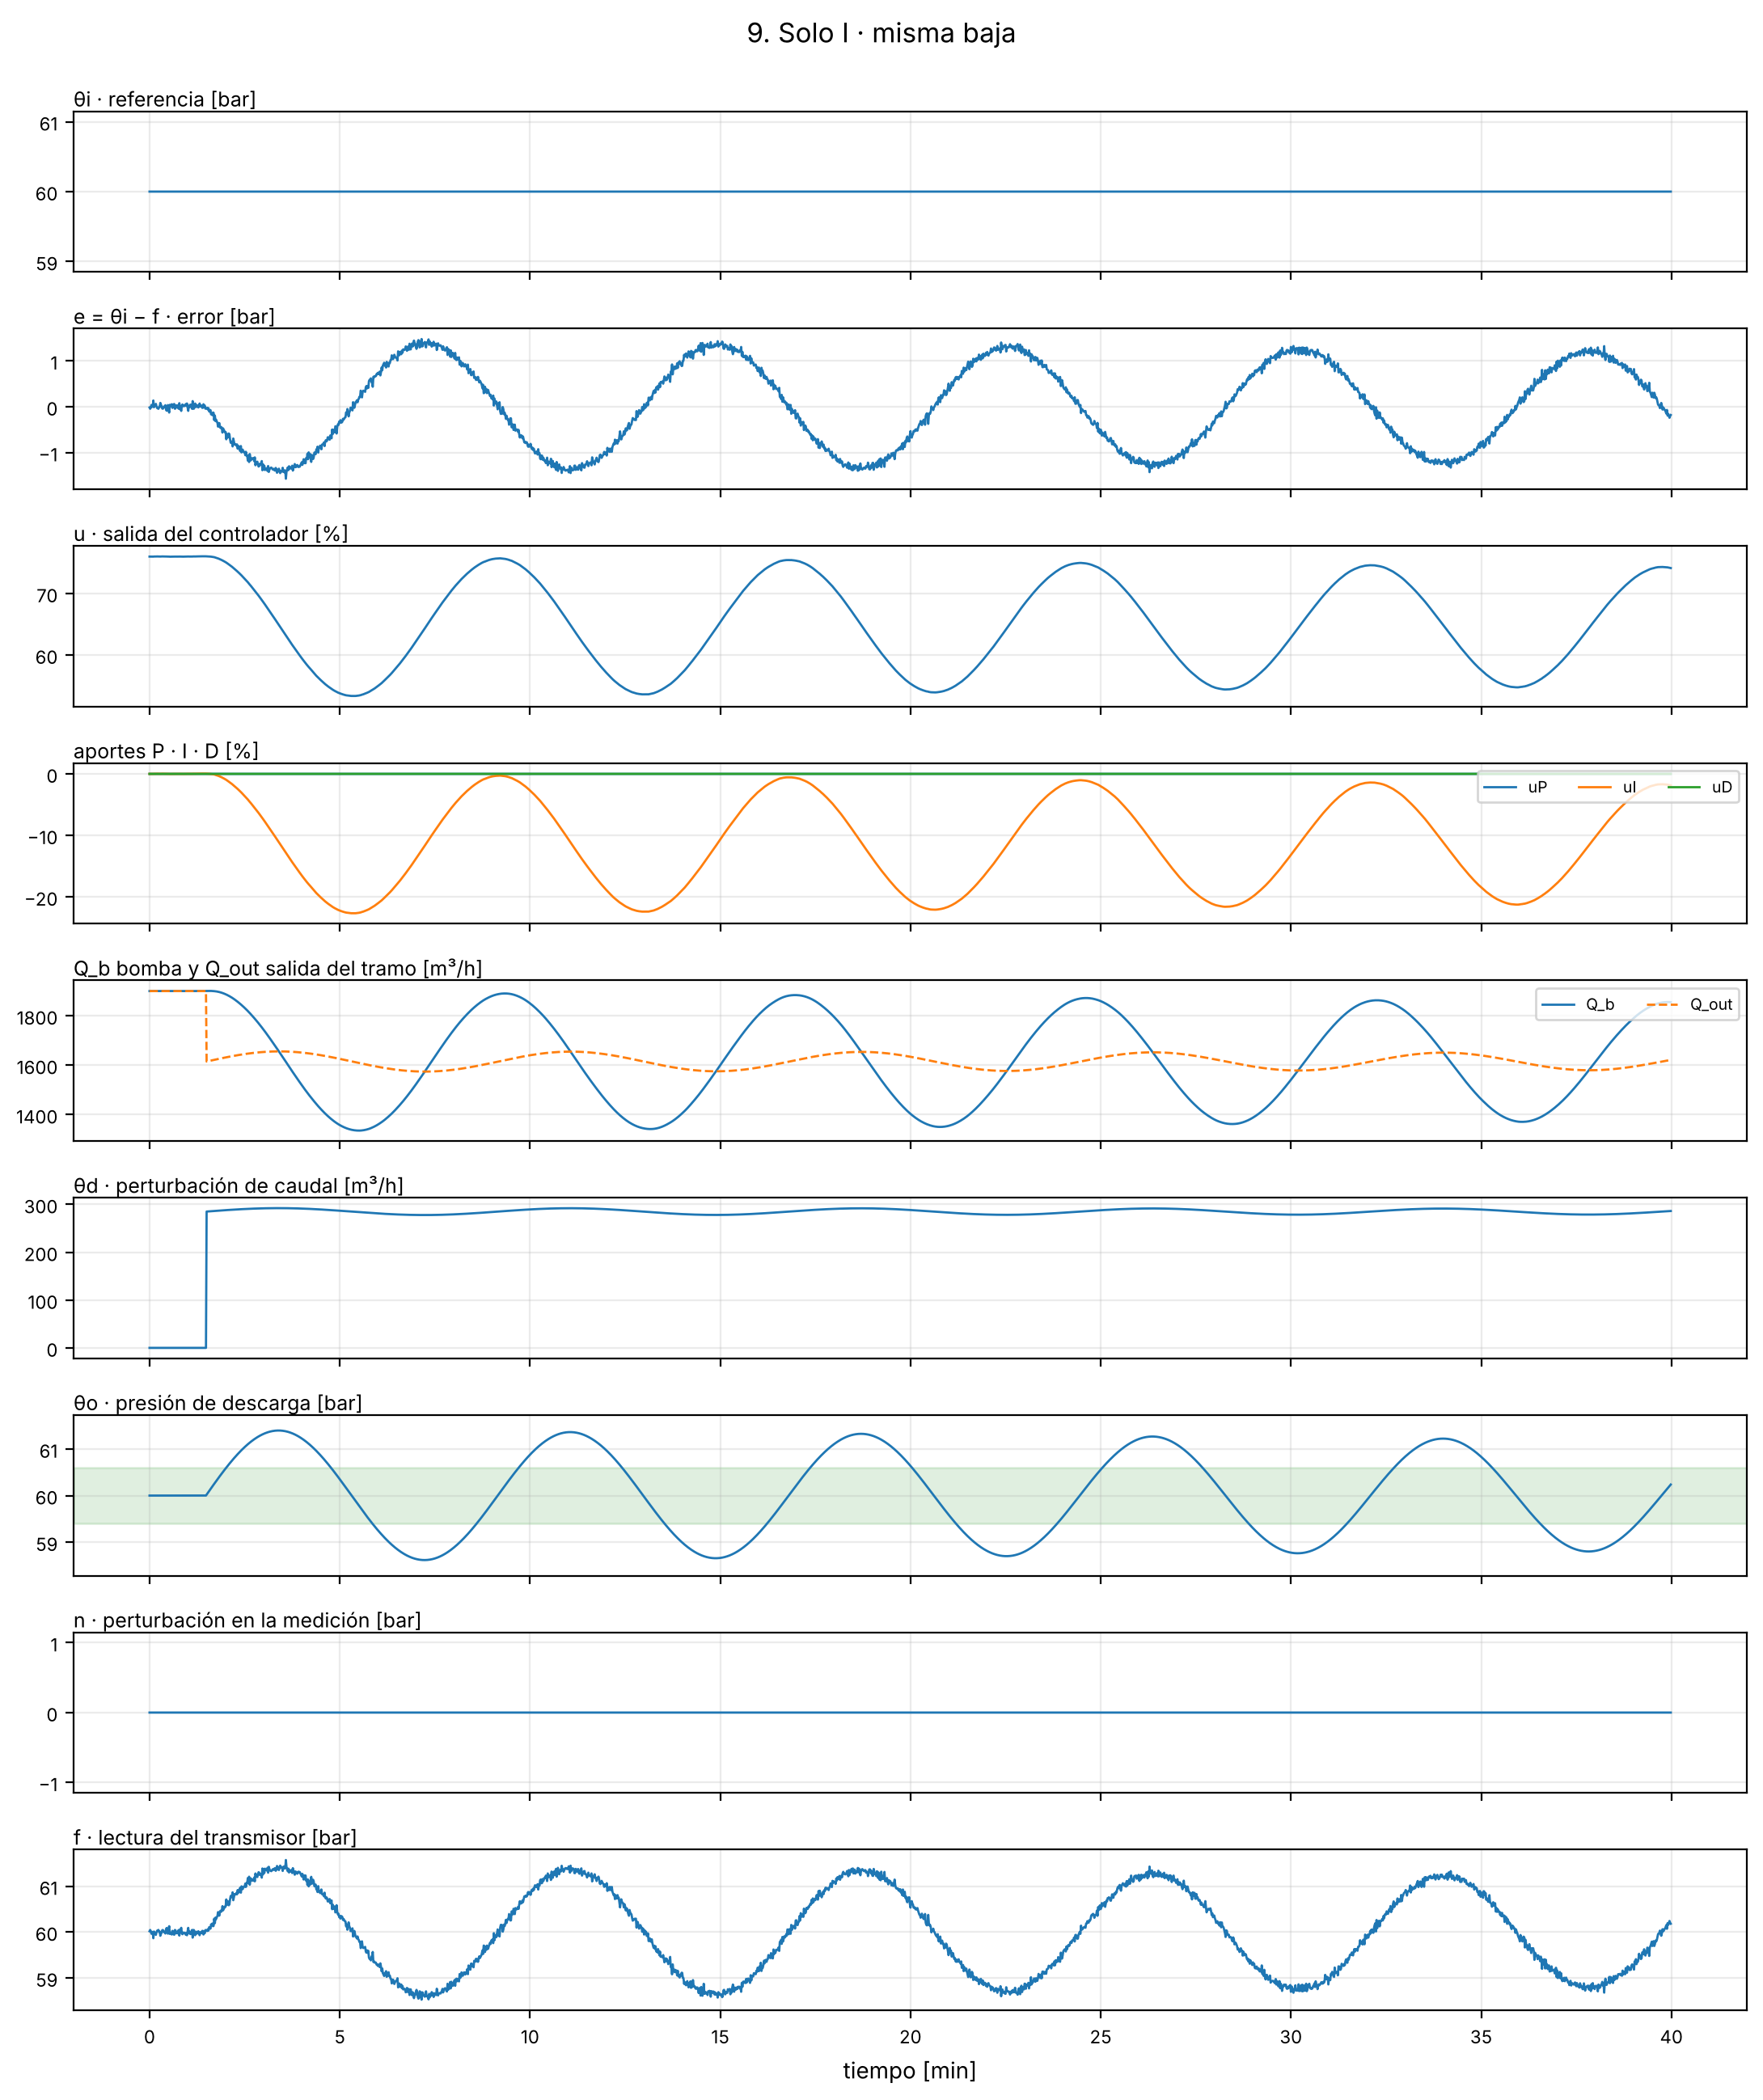

In [14]:
escenario("9. Solo I · misma baja")

10. Solo D · misma baja (Kv = 5)
   00:44  θo sale de la banda (60.60 bar)
   02:44  FALLA: más de 120 s fuera de banda


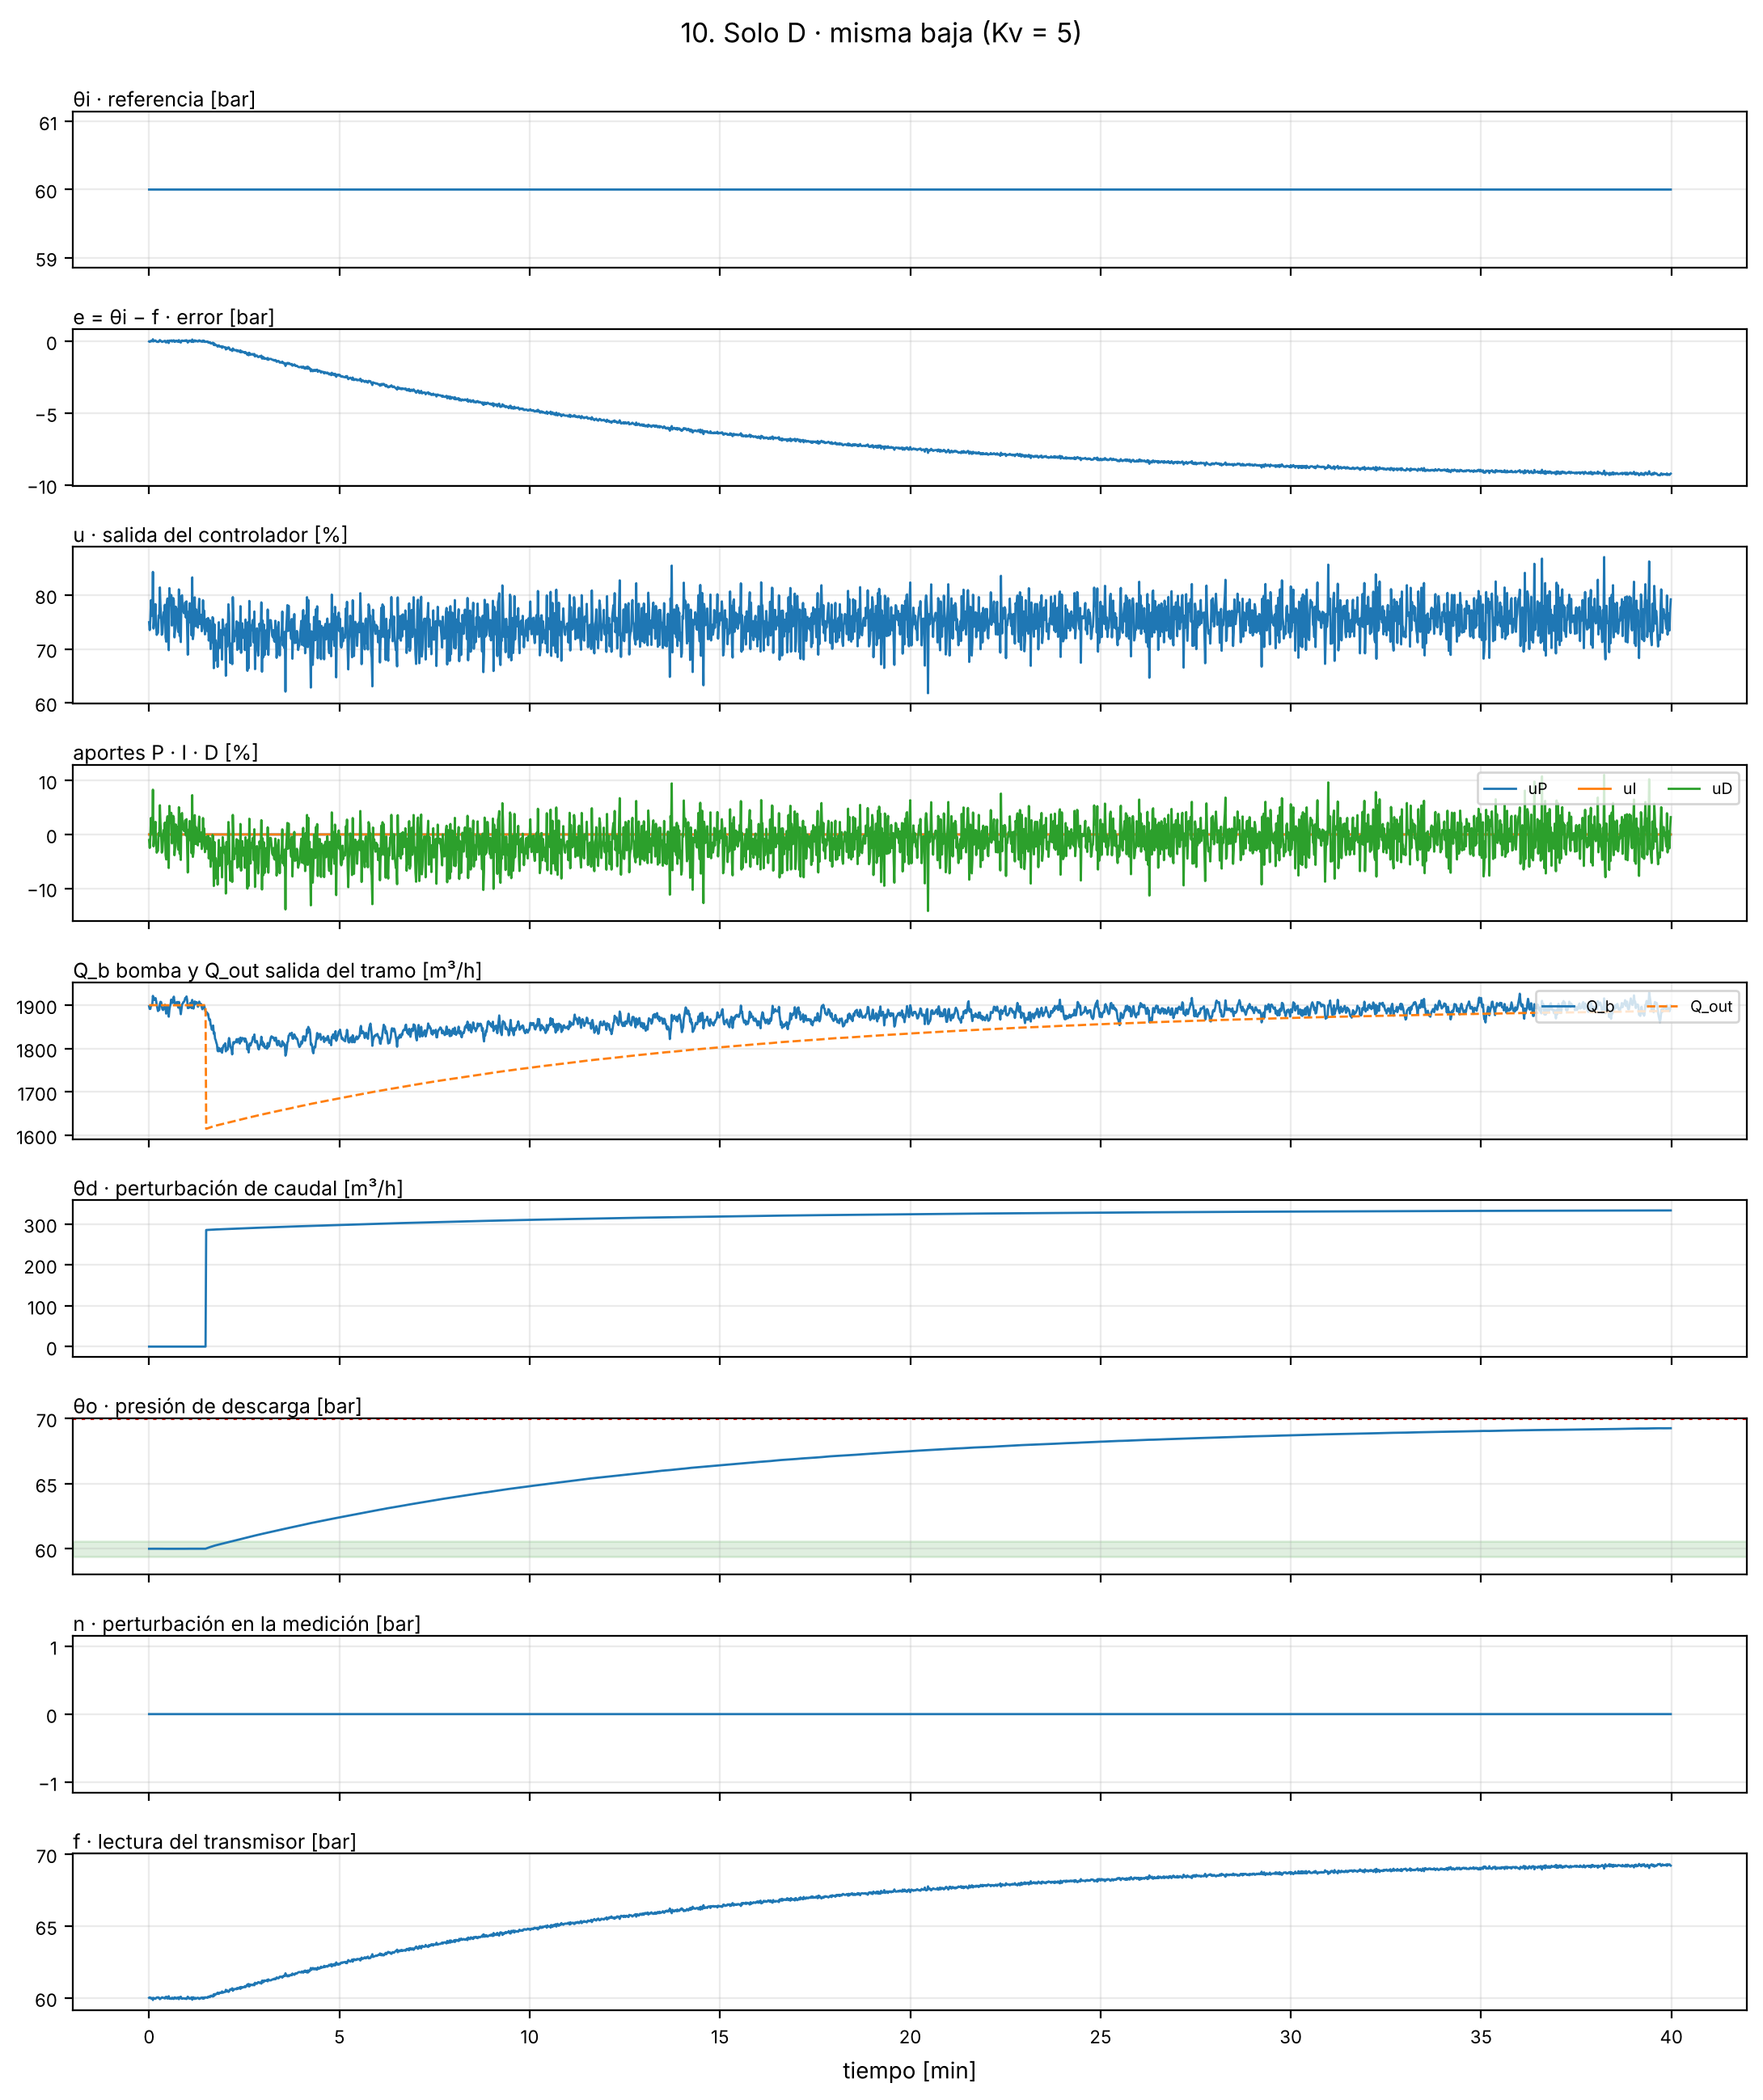

In [15]:
escenario("10. Solo D · misma baja (Kv = 5)")

## 7. Cada acción por separado y error en estado estable
La misma baja de demanda del 15 % con cada acción sola, con las constantes del PI (Kp = 10 % por bar, Ki = 6,67 % por bar·min) y Kv = 5 %·min por bar para la derivativa. El **error en estado estable** se toma como el promedio de e = θi − f en el último minuto, igual que el indicador *Error medio 1 min* del tablero. Con e = θi − f, un error negativo significa que la presión quedó por encima de la referencia.

Ley de control                   pico   error final   máx. fuera seguido   desvío de u
Sin control (lazo abierto)     +9.62      -9.61 bar            2309 s       0.00 %
Solo P                         +1.03      -1.02 bar            2301 s       0.51 %
Solo I                         +1.40      -0.22 bar             164 s       7.00 %
Solo D                         +9.26      -9.25 bar            2297 s       3.29 %
PI (elegido)                   +0.72      +0.00 bar              83 s       0.51 %
PID (Kv = 5)                   +0.63      +0.00 bar              45 s       3.79 %


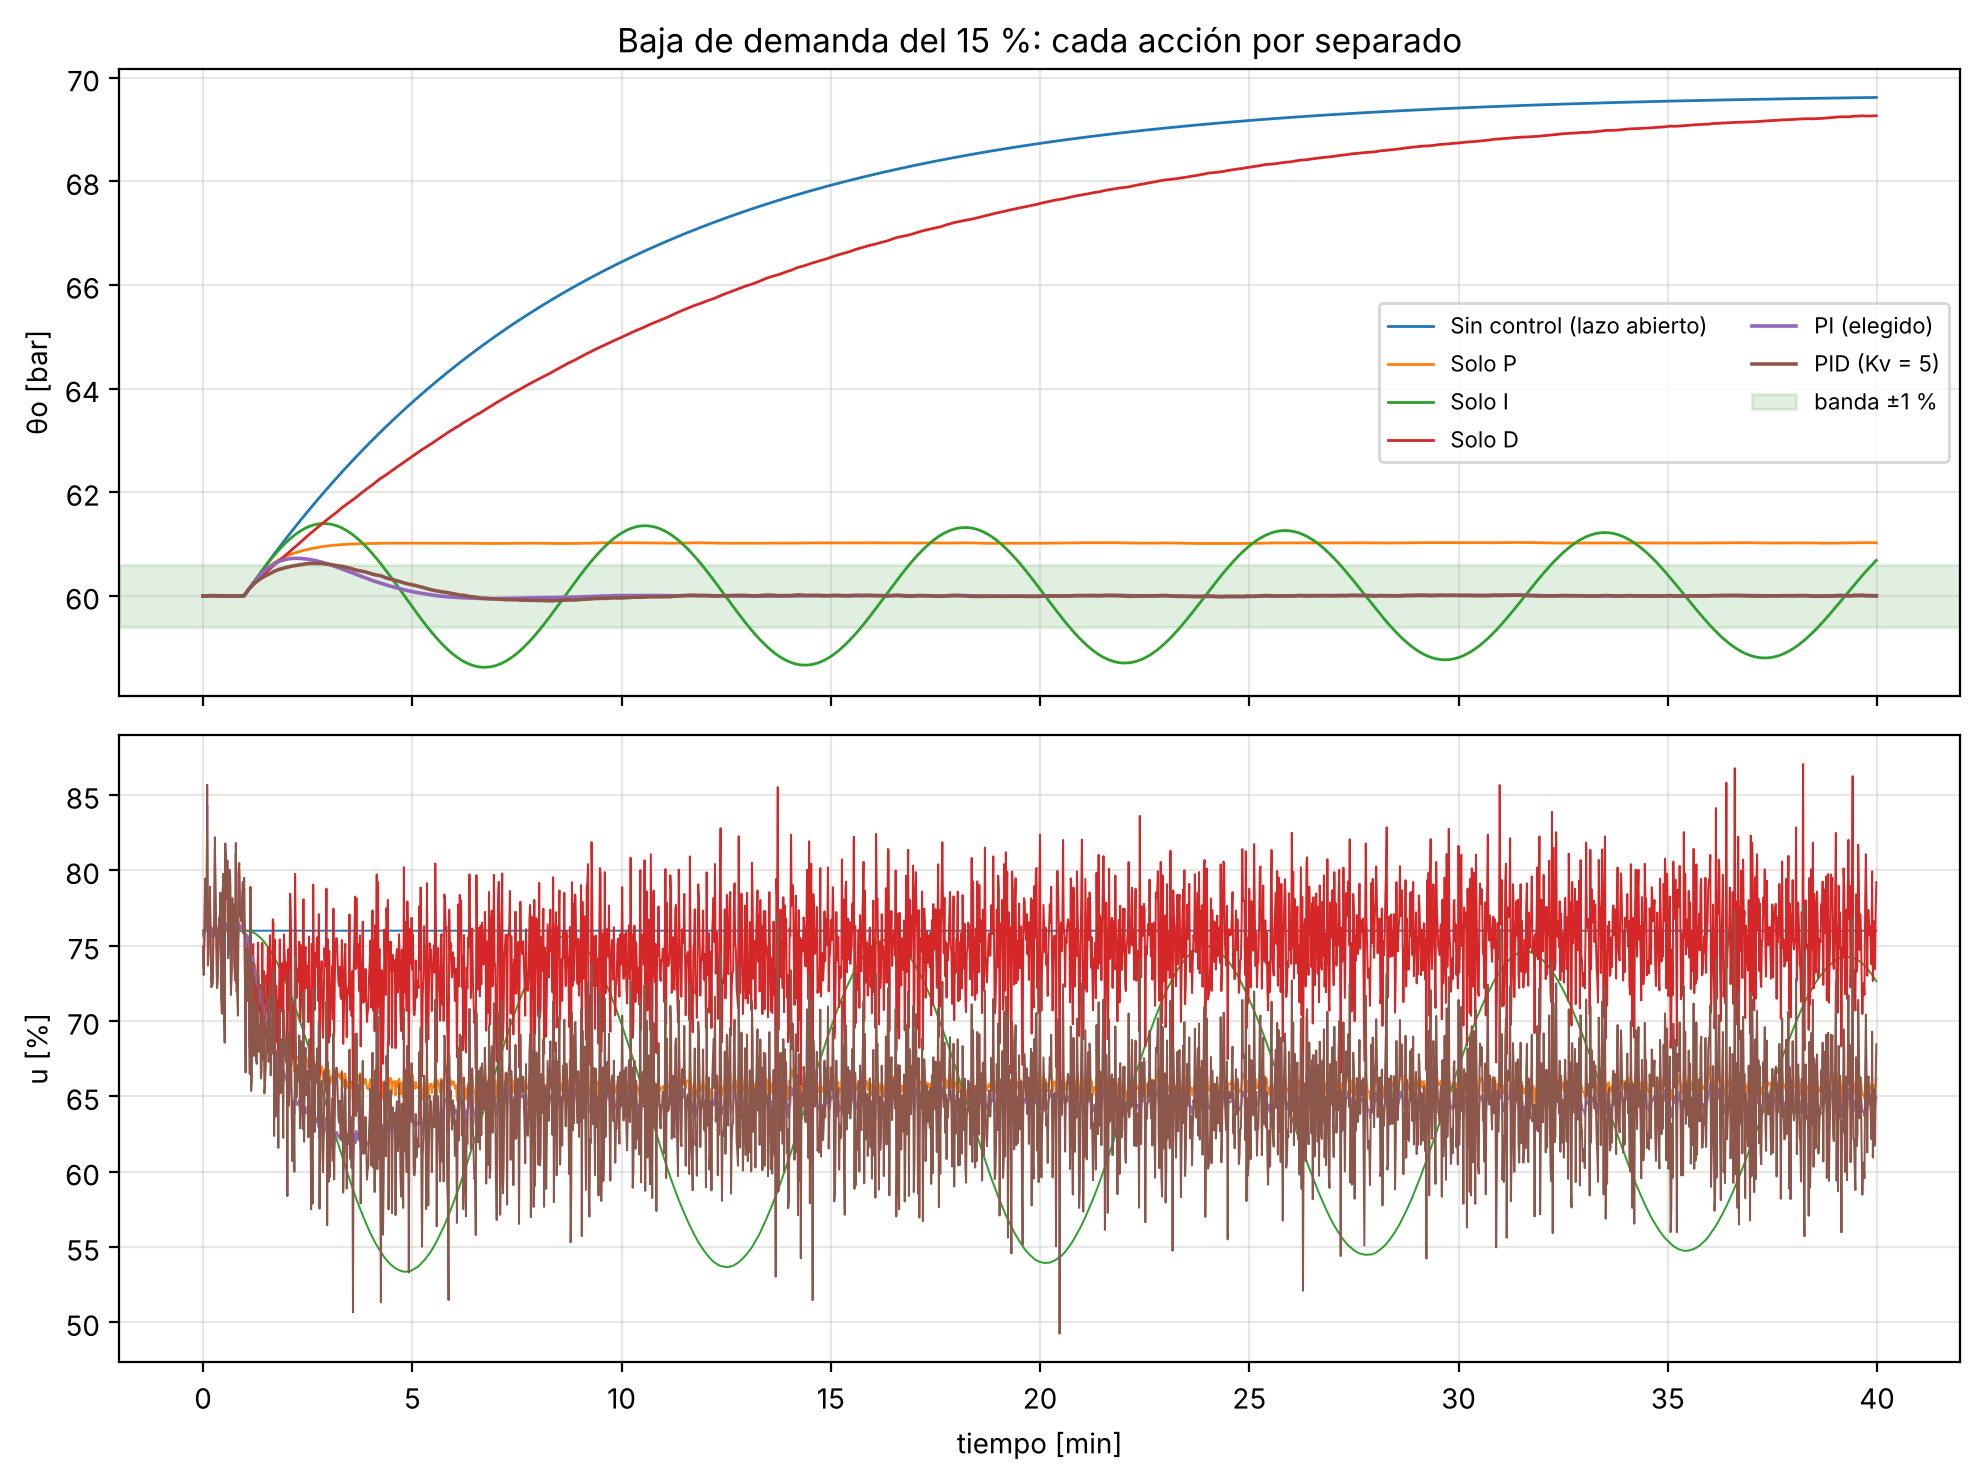

In [16]:
ACCIONES = [("Sin control (lazo abierto)", 0.0, 0.0, 0.0), ("Solo P", KP, 0.0, 0.0), ("Solo I", 0.0, KI, 0.0),
            ("Solo D", 0.0, 0.0, 5.0), ("PI (elegido)", KP, KI, 0.0), ("PID (Kv = 5)", KP, KI, 5.0)]
BANDA = 0.01 * P_NOM

def max_seguido(fuera):
    """Máximo tiempo seguido fuera de banda [s]."""
    corrida = maximo = 0
    for x in fuera:
        corrida = corrida + 1 if x else 0
        maximo = max(maximo, corrida)
    return maximo

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True)
print(f"{'Ley de control':<28}{'pico':>9}{'error final':>14}{'máx. fuera seguido':>21}{'desvío de u':>14}")
for nombre, kp, ki, kv in ACCIONES:
    r, q, _ = correr(kp=kp, ki=ki, kv=kv, tipo="demanda", amp=15, t0=60, total=2400, supervision=False)
    d = r["theta_o"][60:] - P_NOM
    e_ss = r["e"][-60:].mean()
    print(f"{nombre:<28}{d.max():+8.2f} {e_ss:+10.2f} bar{max_seguido(np.abs(d) > BANDA):>16d} s{r['u'][-600:].std():>11.2f} %")
    a1.plot(r["t"] / 60, r["theta_o"], lw=1.3 if "PI" in nombre else 1.0, label=nombre)
    a2.plot(r["t"] / 60, r["u"], lw=0.7, label=nombre)
a1.axhspan(P_NOM - BANDA, P_NOM + BANDA, color="green", alpha=0.12, label="banda ±1 %")
a1.set_ylabel("θo [bar]"); a1.legend(fontsize=8, ncol=2); a1.grid(alpha=0.3)
a1.set_title("Baja de demanda del 15 %: cada acción por separado")
a2.set_ylabel("u [%]"); a2.set_xlabel("tiempo [min]"); a2.grid(alpha=0.3)
fig.tight_layout(); plt.show()

**Cómo se lee.** Sin control la presión se va a 69,7 bar. Solo P frena la subida pero deja 1 bar de error permanente (lazo de tipo 0). Solo I anula el error (tipo 1), pero sin la P oscila casi sin amortiguar. Solo D actúa mientras la presión cambia y después deja de corregir: termina como sin control. El PI combina la reacción de la P con la integral que anula el error; el PID mejora un poco el pico, pero mueve la bomba mucho más por el ruido del transmisor.

## 8. Latencia: margen de fase y demora crítica
Si el lazo se cerrara a través de la nube, la medición llegaría con demora. El margen de fase dice cuánta demora pura tolera el lazo antes de volverse inestable: demora crítica = margen de fase / frecuencia de cruce.

PI (Kp = 10, Ki = 6.67 % por bar·min): margen de fase 55°, cruce 1.16 rad/min, demora crítica 50 s
  demora  0 s: pico 0.73 bar, oscilación al final ±0.00 bar
  demora 30 s: pico 1.13 bar, oscilación al final ±0.00 bar
  demora 50 s: pico 1.45 bar, oscilación al final ±1.25 bar


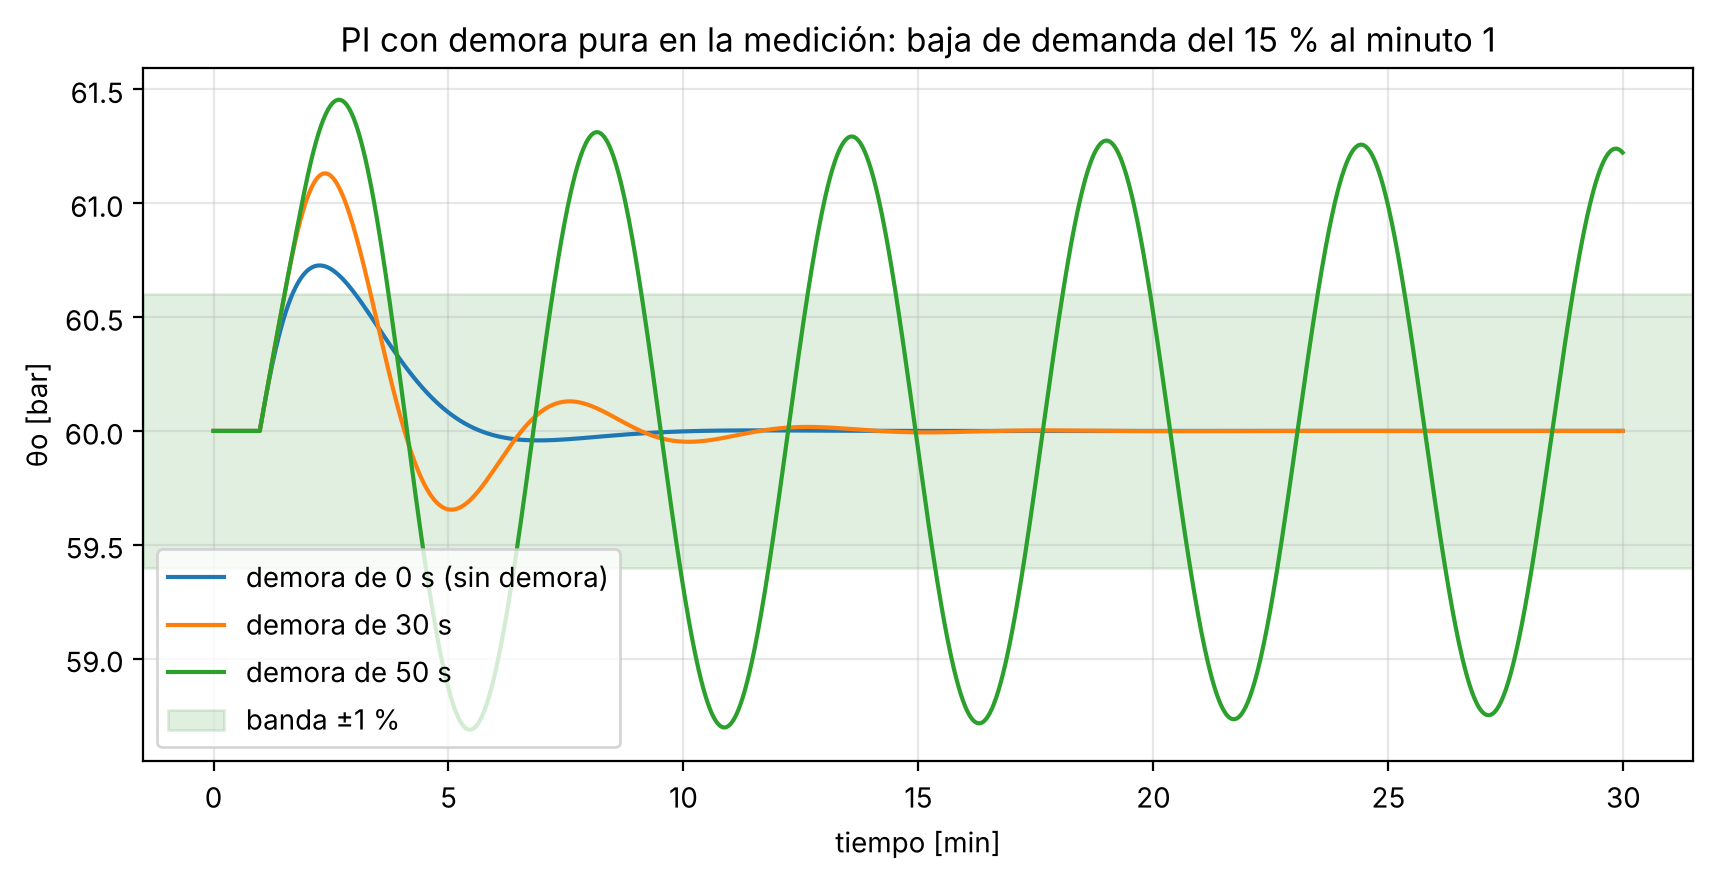

In [17]:
def margen_y_demora(kp=KP, ki=KI):
    """Margen de fase del lazo abierto Gc·Ga·Gp·H y demora pura que lo lleva al límite de estabilidad."""
    wr = np.logspace(-1, 4, 200000)                       # rad/h
    s = 1j * wr
    L_ab = (kp + ki / s) * K_B / (TAU_V * s + 1) / K_OUT / (C_L / K_OUT * s + 1) / (TAU_T * s + 1)
    i = np.argmin(np.abs(np.abs(L_ab) - 1))
    mf = np.degrees(np.angle(L_ab[i])) + 180
    return mf, wr[i] / 60, np.radians(mf) / wr[i] * 3600   # grados, rad/min, segundos


def con_demora(demora_s, kp=KP, ki=KI, minutos=30):
    """PI sin ruido con una demora pura en la medición; la demanda baja 15 % al minuto."""
    th, Qb, Pm, integ = P_NOM, Q_NOM, P_NOM, 0.0
    cola, k_out, h = [P_NOM] * demora_s, K_OUT, []
    for k in range(minutos * 60):
        if k == 60:
            k_out = 0.85 * K_OUT
        Pm += TS / TAU_T * (th - Pm)
        cola.append(Pm); f = cola.pop(0)
        err = P_NOM - f
        u = U0 + kp * err + ki * integ
        if 0 < u < 100:
            integ += err * TS
        u = min(max(u, 0.0), 100.0)
        Qb += TS / TAU_V * (K_B * u - Qb)
        th += TS * (Qb - k_out * (th - P_SIG)) / C_L
        h.append(th)
    return np.array(h)


mf, wc, dc = margen_y_demora()
print(f"PI (Kp = {KP:g}, Ki = {KI/60:.2f} % por bar·min): margen de fase {mf:.0f}°, cruce {wc:.2f} rad/min, demora crítica {dc:.0f} s")
fig, ax = plt.subplots(figsize=(10, 4.5))
for dem in (0, 30, 50):
    h = con_demora(dem)
    print(f"  demora {dem:2d} s: pico {h[60:].max() - P_NOM:.2f} bar, oscilación al final ±{np.abs(h[-300:] - P_NOM).max():.2f} bar")
    ax.plot(np.arange(len(h)) / 60, h, label=f"demora de {dem} s" + (" (sin demora)" if dem == 0 else ""))
ax.axhspan(P_NOM - 0.6, P_NOM + 0.6, color="green", alpha=0.12, label="banda ±1 %")
ax.set_xlabel("tiempo [min]"); ax.set_ylabel("θo [bar]"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("PI con demora pura en la medición: baja de demanda del 15 % al minuto 1")
plt.show()

Una conexión a la nube demora de décimas de segundo a pocos segundos, así que la latencia promedio no desestabilizaría este lazo, que es lento. El problema es que la demora no es constante y el enlace puede cortarse: por eso el PI y las protecciones quedan en el PLC y la nube recibe los datos en forma asíncrona (MQTT con broker). Ver el Anexo del informe.

## 9. Tablero: simulación en tiempo real
Se configuran la referencia, Kp, Ki, Kv, qué acciones están habilitadas (casillas P, I y D; una acción deshabilitada vale cero sin perder su constante), el tipo de perturbación, su amplitud, su duración (0 = sostenida) y el criterio de QoS, y se presiona **Iniciar**. La simulación arranca en condiciones normales, corre en vivo (mostrando los últimos 10 minutos) y al minuto y medio (01:30) aplica la perturbación de golpe. Ese primer minuto y medio en régimen es el que necesita la detección de fugas para llenar su promedio de 30 s.

* Para **detenerla** en un instante, usá el botón de detener de la celda (en Colab, el cuadrado a la izquierda). Queda congelada en ese momento.
* **Velocidad**: segundos de proceso por cada segundo real (1 = tiempo real del proceso).

Necesita `ipywidgets`, que ya viene en Colab y en Jupyter.

In [18]:
import time
from IPython.display import display, clear_output
import ipywidgets as w

st = dict(layout=w.Layout(width="420px"), style={"description_width": "190px"})
c_vn = w.FloatSlider(value=60, min=40, max=68, step=0.5, description="Referencia θi [bar]", **st)
c_kp = w.FloatSlider(value=10, min=0, max=200, step=1, description="Kp [% por bar]", **st)
c_ki = w.FloatSlider(value=6.67, min=0, max=120, step=0.01, description="Ki [% por bar·min]", **st)
c_kv = w.FloatSlider(value=0, min=0, max=20, step=0.1, description="Kv [%·min por bar]", **st)
c_tipo = w.Dropdown(options=[("Baja de demanda [%]", "demanda"), ("Fuga [m³/h]", "fuga"), ("Error en el transmisor n [bar]", "medicion"), ("Sin perturbación", None)],
                    value="demanda", description="Perturbación", **st)
c_amp = w.FloatText(value=15, description="Amplitud", **st)
c_dur = w.IntText(value=0, description="Duración [s] (0 = sostenida)", **st)
c_banda = w.FloatText(value=1.0, description="Banda admisible [± %]", **st)
c_tol = w.IntText(value=120, description="Tolerado fuera de banda [s]", **st)
c_sup = w.Checkbox(value=True, description="Supervisión activa")
c_P = w.Checkbox(value=True, description="Acción P")
c_I = w.Checkbox(value=True, description="Acción I")
c_D = w.Checkbox(value=True, description="Acción D")
c_vel = w.Dropdown(options=[1, 10, 30, 60], value=30, description="Velocidad [×]", **st)
c_tot = w.IntText(value=690, description="Duración total [s]", **st)
b_ini = w.Button(description="Iniciar", button_style="primary")
salida = w.Output()

VENTANA, CUADRO = 600, 0.25                 # s visibles y segundos reales por cuadro

def vivo(_=None):
    # Una acción deshabilitada vale cero en el PLC
    lazo = Lazo(c_kp.value if c_P.value else 0.0, c_ki.value * 60 if c_I.value else 0.0,
                c_kv.value if c_D.value else 0.0, c_vn.value, c_sup.value)
    q, t0 = QoS(c_banda.value, c_tol.value), 90
    reg = {k: [] for k in ["t", "theta_i", "e", "u", "uP", "uI", "uD", "Q_b", "Q_out", "theta_d", "theta_o", "n", "f"]}
    pasos_por_cuadro = max(1, int(c_vel.value * CUADRO))
    fig, axs = plt.subplots(9, 1, figsize=(11, 13), sharex=True)
    plt.close(fig)
    try:
        for k in range(c_tot.value):
            activa = c_tipo.value is not None and k >= t0 and (c_dur.value == 0 or k < t0 + c_dur.value)
            aplicar(lazo, c_tipo.value if activa else None, c_amp.value)
            antes = lazo.parada
            s = lazo.paso()
            if lazo.parada is not None and antes is None:
                q.eventos.append(f"{(k - t0) // 60:02d}:{(k - t0) % 60:02d}  PARADA por {lazo.motivo}")
            q.evaluar(s, lazo.vn, t0)
            for key in reg:
                reg[key].append(s[key]); reg[key] = reg[key][-VENTANA:]
            if k % pasos_por_cuadro == 0 or k == c_tot.value - 1:
                estado = ("PARADA por " + lazo.motivo if lazo.parada is not None else "FALLA de QoS" if q.falla
                          else "fuera de banda" if q.fuera is not None else "perturbación aplicada" if activa else "normal")
                graficar({kk: np.array(v) for kk, v in reg.items()}, f"t = {k//60:02d}:{k%60:02d}  ·  {estado}  ·  θo = {s['theta_o']:.2f} bar  ·  fallas: {q.fallas}",
                         lazo.vn, c_banda.value, axs)
                with salida:
                    clear_output(wait=True)
                    display(fig)
                    e_med = np.mean(reg["e"][-60:])
                    print(f"Error medio del último minuto (SP − PV): {e_med:+.2f} bar"
                          + ("  ← error permanente fuera de banda" if abs(e_med) > lazo.vn * c_banda.value / 100 else ""))
                    print("\n".join(q.eventos[-8:]))
                time.sleep(CUADRO)
    except KeyboardInterrupt:
        with salida:
            print(f"Simulación detenida en t = {k//60:02d}:{k%60:02d}")

b_ini.on_click(vivo)
display(w.HBox([w.VBox([c_vn, c_kp, c_ki, c_kv, w.HBox([c_P, c_I, c_D]), c_sup]), w.VBox([c_tipo, c_amp, c_dur, c_banda, c_tol, c_vel, c_tot, b_ini])]), salida)

Output()